# Portfolioopdracht 1. Voorspel herseninfarct

In deze opdracht ontwikkelen en vergelijken we verschillende machine-learningmodellen om te voorspellen of een patiënt een verhoogd risico heeft op een herseninfarct. We analyseren en verwerken de data, evalueren modellen met geschikte metrics en verbeteren de prestaties met onder andere cross-validation, hyperparameter tuning en technieken voor imbalanced data. De modellen worden getest via Kaggle en uiteindelijk vergelijken we de resultaten om een onderbouwd modeladvies te geven.

### Groepsinformatie
#### Teamleden: 
Alisha 

Shalini

Baset

#### Teamnaam Kaggle: ABS

#### Gebruikersnamen Kaggle:
Alisha - alisharampersad

Shalini - shalinibekaroe

Baset - basetpaiman

## 1 - Exploratieve Data Analyse (EDA)

In dit hoofdstuk wordt de trainingsdataset onderzocht. Eerst bekijken we de structuur van de dataset en de betekenis van de verschillende kolommen. Daarna controleren we of de data geschikt is om te gebruiken voor Machine Learning met Scikit-learn.

In [36]:
#dataset inspecteren
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix, classification_report)


df = pd.read_csv("train.csv")

df.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


### 1.3 Uitleg van de kolommen

| Kolom | Uitleg | Datatype |
|---|---|---|
| `id` | Uniek identificatienummer van een patiënt. | `int64` |
| `age` | Leeftijd van de patiënt. | `float64` |
| `hypertension` | Geeft aan of de patiënt hypertensie (hoge bloeddruk) heeft. `1` = ja en `0` = nee. | `int64` |
| `heart_disease` | Geeft aan of de patiënt een hartaandoening heeft. `1` = ja en `0` = nee. | `int64` |
| `avg_glucose_level` | Gemiddeld glucosegehalte van de patiënt. | `float64` |
| `bmi` | Body Mass Index (BMI) van de patiënt. | `float64` |
| `gender_Female` | Dummyvariabele die aangeeft of de patiënt vrouw is. True betekent hier dat de patiënt een vrouw is. | `bool` |
| `gender_Male` | Dummyvariabele die aangeeft of de patiënt man is. True betekent hier dat de patiënt een man is. | `bool` |
| `gender_Other` | Dummyvariabele voor patiënten met een andere geregistreerde gendercategorie. True betekent hier dat de patiënt tot deze categorie behoort. | `bool` |
| `ever_married_No` | Dummyvariabele die aangeeft dat de patiënt nooit getrouwd is geweest. True betekent hier dat de patiënt nooit getrouwd is geweest. | `bool` |
| `ever_married_Yes` | Dummyvariabele die aangeeft dat de patiënt getrouwd is of is geweest. True betekent hier dat de patiënt getrouwd is of is geweest. | `bool` |
| `work_type_Govt_job` | Dummyvariabele die aangeeft dat de patiënt bij de overheid werkt. True betekent hier dat de patiënt bij de overheid werkt. | `bool` |
| `work_type_Never_worked` | Dummyvariabele die aangeeft dat de patiënt nooit heeft gewerkt. True betekent hier dat de patiënt nooit heeft gewerkt. | `bool` |
| `work_type_Private` | Dummyvariabele die aangeeft dat de patiënt in de private sector werkt. True betekent hier dat de patiënt in de private sector werkt. | `bool` |
| `work_type_Self-employed` | Dummyvariabele die aangeeft dat de patiënt zelfstandig ondernemer is. True betekent hier dat de patiënt zelfstandig ondernemer is. | `bool` |
| `work_type_children` | Dummyvariabele die aangeeft dat de patiënt tot de categorie kinderen behoort. True betekent hier dat de patiënt tot de categorie kinderen behoort. | `bool` |
| `Residence_type_Rural` | Dummyvariabele die aangeeft dat de patiënt in een landelijk gebied woont. True betekent hier dat de patiënt in een landelijk gebied woont. | `bool` |
| `Residence_type_Urban` | Dummyvariabele die aangeeft dat de patiënt in een stedelijk gebied woont. True betekent hier dat de patiënt in een stedelijk gebied woont. | `bool` |
| `smoking_status_formerly smoked` | Dummyvariabele die aangeeft dat de patiënt vroeger heeft gerookt. True betekent hier dat de patiënt vroeger heeft gerookt. | `bool` |
| `smoking_status_never smoked` | Dummyvariabele die aangeeft dat de patiënt nooit heeft gerookt. True betekent hier dat de patiënt nooit heeft gerookt. | `bool` |
| `smoking_status_smokes` | Dummyvariabele die aangeeft dat de patiënt momenteel rookt. True betekent hier dat de patiënt momenteel rookt. | `bool` |
| `stroke` | Doelvariabele. Geeft aan of de patiënt een beroerte heeft gehad. `1` = ja en `0` = nee. | `int64` |

In [37]:
#check of dataset voldoet aan eisen voor machine learning 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          33550 non-n

### 1.4.1 ML vereisten
De data voldoet aan de eisen om machine learning toe te passen:

1.) De data is numeriek: De categorische variabelen zijn al grotendeels omgezet naar dummyvariabelen. Hierdoor zijn deze variabelen numeriek weergegeven.

2.) De data is in een Pandas Dataframe

3.) De data bevat geen missende waardes -> dit kunnen we zien aan 'non-null' bij alle kolommen

### 1.4.2 Datatypes en basisstatistieken

In [38]:
#datatypes weergeven
display(df.dtypes)


id                                  int64
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Female                        bool
gender_Male                          bool
gender_Other                         bool
ever_married_No                      bool
ever_married_Yes                     bool
work_type_Govt_job                   bool
work_type_Never_worked               bool
work_type_Private                    bool
work_type_Self-employed              bool
work_type_children                   bool
Residence_type_Rural                 bool
Residence_type_Urban                 bool
smoking_status_formerly smoked       bool
smoking_status_never smoked          bool
smoking_status_smokes                bool
stroke                              int64
dtype: object

##### Toelichting datatypes

Een `float` is een getal met decimalen, bijvoorbeeld `45.5`.

Een `integer` is een geheel getal zonder decimalen, bijvoorbeeld `45`.

Een `boolean` is een waarde die `True` of `False` kan zijn. `True` betekent `1` en `False` betekent `0`.

In [39]:
#basisstatistieken weergeven
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000


### 1.4.3 Relaties tussen de onafhankelijke variabelen en stroke

De afhankelijke variabele is `stroke` (0 = geen herseninfarct, 1 = wel) en alle andere kolommen (behalve `id`) zijn de onafhankelijke variabelen en omdat maar ongeveer 1,5% van de patienten stroke heeft, kijken we vooral naar percentages en niet naar aantallen anders is de stroke-groep in de grafieken bijna niet te zien.

we doen dit in vier stappen:
1. correlatie van iedere variabele met stroke (eerste overzicht)
2. boxplots van de numerieke variabelen (`age`, `avg_glucose_level`, `bmi`)
3. percentage stroke per groep voor de ja/nee-kolommen (hypertensie, hartziekte en de dummykolommen)
4. percentage stroke per leeftijdsgroep

#### Stap 1: correlatie tussen alle kolommen (Heatmap)

De correlatie laat zien hoe sterk twee kolommen samenhangen (tussen -1 en 1). Positief betekent: als de ene hoger is, is de andere meestal ook hoger. Negatief betekent het omgekeerde. In een heatmap zien we de correlatie tussen alle kolommen tegelijk. Rood is positief, blauw is negatief en wit is (bijna) geen verband. De onderste rij (`stroke`) laat de relatie met de onafhankelijke variabele zien.

De True/False-kolommen zetten we hiervoor om naar 1/0. De kolom `id` laten we weg, want dat is alleen een patiëntnummer.

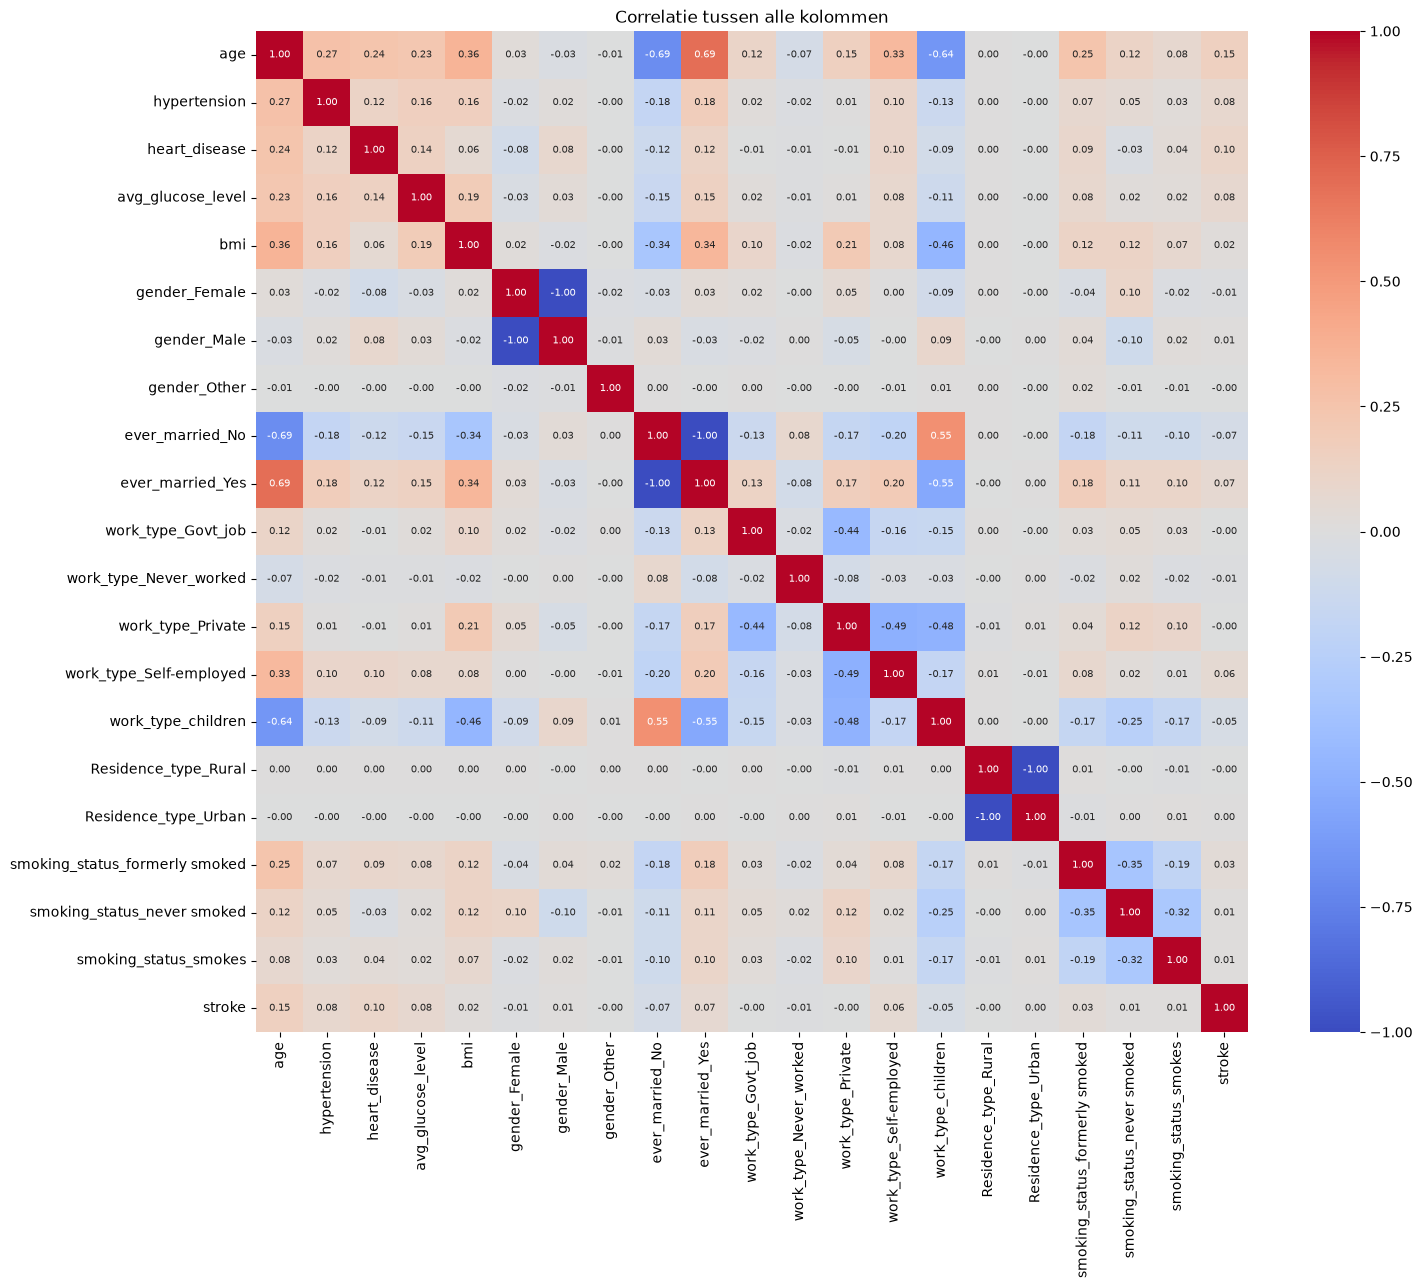

In [40]:
# importeren voor de grafieken

# id weglaten en True/False omzetten naar 1/0 zodat we kunnen rekenen
df_num = df.drop(columns=["id"]).astype(float)

# correlatiematrix: correlatie tussen alle kolommen
correlaties = df_num.corr()

# heatmap met de waarde in ieder vakje (2 decimalen)
plt.figure(figsize=(16, 13))
sns.heatmap(correlaties, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlatie tussen alle kolommen")
plt.show()

##### Toelichting
- **Relatie met stroke (onderste rij):** `age` heeft de sterkste correlatie met stroke (0,15), daarna `heart_disease` (0,10), `hypertension` (0,08) en `avg_glucose_level` (0,08). `bmi`, gender en woonplaats hebben bijna geen correlatie. Alle correlaties met stroke zijn klein; dat komt ook doordat stroke zo weinig voorkomt. Daarom bekijken we de variabelen hieronder ook nog apart.
- **Relaties tussen de onafhankelijke variabelen:** `age` hangt sterk samen met `ever_married_Yes` (0,69) en negatief met `work_type_children` (-0,64). Ouderen zijn vaker getrouwd en kinderen zijn jong. We kunnen aannemen dat als getrouwde mensen vaker stroke hebben, kan dat door hun leeftijd komen.
- **Dummykolommen:** paren als `gender_Female`/`gender_Male`, `ever_married_No`/`ever_married_Yes` en `Residence_type_Rural`/`Residence_type_Urban` hebben een correlatie van -1,00. Ze zijn elkaars tegenovergestelde en bevatten dus dezelfde informatie.

#### Stap 2: numerieke variabelen (boxplots)

Met een boxplot vergelijken we de verdeling van `age`, `avg_glucose_level` en `bmi` tussen patiënten zonder stroke (0) en met stroke (1). De streep in de doos is de mediaan; de doos bevat de middelste 50% van de patiënten.

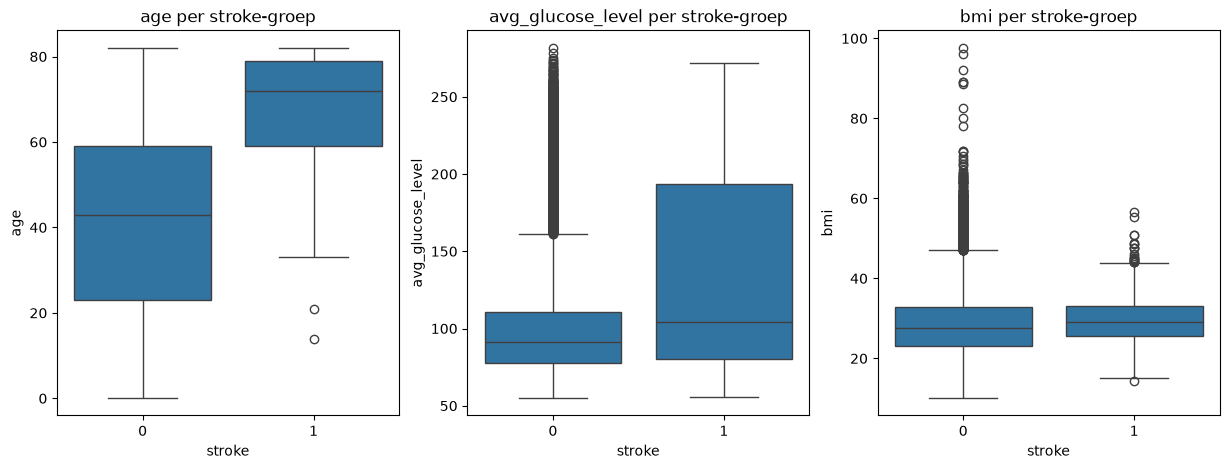

In [41]:
# drie boxplots naast elkaar: per variabele stroke 0 tegenover stroke 1
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, kolom in zip(axes, ["age", "avg_glucose_level", "bmi"]):
    sns.boxplot(data=df, x="stroke", y=kolom, ax=ax)
    ax.set_title(f"{kolom} per stroke-groep")
plt.show()

##### Toelichting
- **age**: patiënten met stroke zijn duidelijk ouder. De mediane leeftijd is ongeveer 72 jaar bij stroke en ongeveer 43 jaar zonder stroke.
- **avg_glucose_level**: bij stroke ligt de mediaan hoger (ongeveer 104 tegenover 91) en de doos loopt veel verder omhoog. Een deel van de stroke-patiënten heeft dus een hoog glucosegehalte.
- **bmi**: de boxen lijken erg op elkaar dus BMI hangt weinig samen met stroke. Er zijn wel uitschieters met een extreem hoge BMI (tot 97,6) voor geen stroke-patiënten.

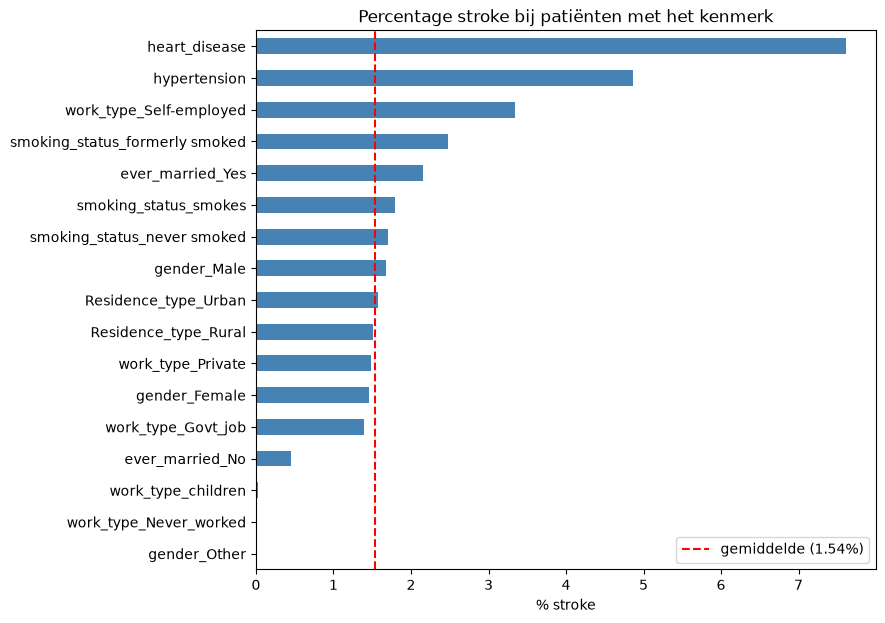

gender_Other                      0.00
work_type_Never_worked            0.00
work_type_children                0.02
ever_married_No                   0.45
work_type_Govt_job                1.40
gender_Female                     1.45
work_type_Private                 1.49
Residence_type_Rural              1.51
Residence_type_Urban              1.57
gender_Male                       1.67
smoking_status_never smoked       1.70
smoking_status_smokes             1.79
ever_married_Yes                  2.16
smoking_status_formerly smoked    2.47
work_type_Self-employed           3.34
hypertension                      4.87
heart_disease                     7.62
dtype: float64

In [42]:
# functie: percentage stroke bij patiënten waarbij de kolom 1 (True) is
def stroke_percentage(kolom):
    groep = df[df[kolom] == 1]
    return groep["stroke"].mean() * 100


# alle ja/nee-kolommen (alles behalve id, de numerieke kolommen en stroke)
ja_nee_kolommen = df.columns.drop(
    ["id", "age", "avg_glucose_level", "bmi", "stroke"])

# percentage per kolom berekenen en sorteren
percentages = pd.Series(
    {kolom: stroke_percentage(kolom) for kolom in ja_nee_kolommen}
).sort_values()

# gemiddelde percentage stroke in de hele dataset
gemiddelde = df["stroke"].mean() * 100

# staafgrafiek met het gemiddelde als stippellijn
percentages.plot(kind="barh", figsize=(8, 7), color="steelblue")
plt.axvline(gemiddelde, color="red", linestyle="--",
            label=f"gemiddelde ({gemiddelde:.2f}%)")
plt.title("Percentage stroke bij patiënten met het kenmerk")
plt.xlabel("% stroke")
plt.legend()
plt.show()

percentages.round(2)

##### Toelichting
- **heart_disease** (7,62%) en **hypertension** (4,87%) hebben het hoogste percentage stroke: veel hoger dan het gemiddelde van 1,54%.
- **work_type_Self-employed** (3,34%), **smoking_status_formerly smoked** (2,47%) en **ever_married_Yes** (2,16%) liggen ook boven het gemiddelde. Dit zijn vaak oudere mensen, dus dit komt waarschijnlijk voor een groot deel door de leeftijd.
- **work_type_children** (0,02%), **work_type_Never_worked** (0%) en **ever_married_No** (0,45%) liggen ver onder het gemiddelde; dit zijn vooral jonge mensen.
- **Residence_type** (Rural 1,51%, Urban 1,57%) en **gender** (vrouw 1,45%, man 1,67%) maken weinig verschil. `gender_Other` heeft 0% maar bestaat uit maar 6 patiënten, dus daar kunnen we niets over zeggen.

#### Stap 4: percentage stroke per leeftijdsgroep

Omdat leeftijd de sterkste relatie heeft, delen we de patiënten op in leeftijdsgroepen van 10 jaar en berekenen we per groep het percentage stroke.

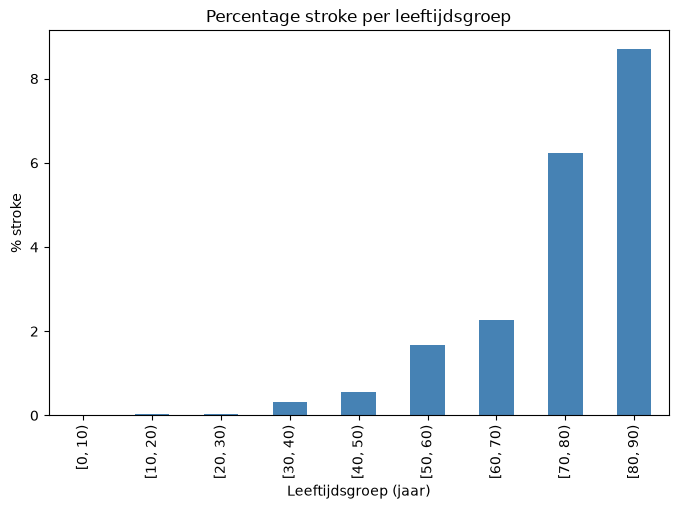

age
[0, 10)     0.00
[10, 20)    0.03
[20, 30)    0.02
[30, 40)    0.33
[40, 50)    0.55
[50, 60)    1.67
[60, 70)    2.28
[70, 80)    6.24
[80, 90)    8.71
Name: stroke, dtype: float64

In [43]:
# leeftijd opdelen in groepen van 10 jaar: [0, 10), [10, 20), ...
leeftijdsgroep = pd.cut(df["age"], bins=range(0, 100, 10), right=False)

# percentage stroke per leeftijdsgroep
per_groep = df.groupby(leeftijdsgroep, observed=True)["stroke"]
stroke_per_leeftijd = per_groep.mean() * 100

# staafgrafiek
stroke_per_leeftijd.plot(kind="bar", figsize=(8, 5), color="steelblue")
plt.title("Percentage stroke per leeftijdsgroep")
plt.xlabel("Leeftijdsgroep (jaar)")
plt.ylabel("% stroke")
plt.show()

stroke_per_leeftijd.round(2)

##### Toelichting
Onder de 30 jaar komt stroke bijna niet voor (0 tot 0,03%). Vanaf 50 jaar stijgt het percentage duidelijk: 1,67% (50–60), 2,28% (60–70), 6,24% (70–80) en 8,71% (80+). Hoe ouder, hoe groter de kans op stroke.

### 1.4.4 Belangrijkste bevindingen van de EDA
1. **De data is sterk ongebalanceerd.** Maar 1,54% van de patienten heeft een herseninfarct gehad. Een model dat altijd "geen stroke" voorspelt, heeft al ongeveer 98,5% accuracy, maar vindt geen enkele stroke-patiënt. Accuracy is dus geen goede maatstaf; we moeten letten op bijvoorbeeld recall en F1-score (Onder stap 2). 
2. **Leeftijd is de belangrijkste variabele.** Stroke komt onder de 30 bijna niet voor en stijgt naar 8,71% bij 80 jaar en ouder (Stap 4).
3. **Hartziekte en hypertensie hangen duidelijk samen met stroke** (7,62% en 4,87% tegenover gemiddeld 1,54%) (Onder stap 2).
4. **Een hoog glucosegehalte hangt samen met stroke.** Stroke-patienten hebben vaker een hoog glucosegehalte (Stap 2). 
5. **Sommige verbanden komen waarschijnlijk door leeftijd.** Getrouwde mensen, zelfstandigen en ex-rokers hebben vaker stroke, maar zijn ook gemiddeld ouder. Kinderen en mensen die nooit gewerkt hebben, hebben bijna nooit stroke omdat ze jong zijn (Onder stap 2).
6. **BMI, geslacht en woonplaats hebben weinig invloed** op stroke (Stap 1).
7. **Geen enkele variabele voorspelt stroke alleen goed.** Zelfs bij 80+ heeft ruim 91% geen stroke (Stap 4). Het model zal daarom meerdere variabelen samen moeten gebruiken en waarschijnlijk ook patienten onterecht als risico aanwijzen. In een medische context is dat minder erg dan een stroke-patient missen.

### 1.4.5 Data opschonen 

In [44]:
def datakwaliteit(df):
    """Geeft een overzicht van mogelijke datakwaliteitsproblemen in de dataset."""
    resultaten = {
        "ontbrekende waarden": df.isna().sum().sum(),
        "dubbele regels (alle kolommen)": df.duplicated().sum(),
        "dubbele patient-id's": df["id"].duplicated().sum(),
        "leeftijd < 0 of > 120": ((df["age"] < 0) | (df["age"] > 120)).sum(),
        "glucose <= 0": (df["avg_glucose_level"] <= 0).sum(),
        "bmi <= 0": (df["bmi"] <= 0).sum(),
    }
    return pd.Series(resultaten)


datakwaliteit(df)

ontbrekende waarden               0
dubbele regels (alle kolommen)    0
dubbele patient-id's              0
leeftijd < 0 of > 120             0
glucose <= 0                      0
bmi <= 0                          0
dtype: int64

##### Toelichting

Er zijn geen ontbrekende waarden, geen dubbele regels en geen dubbele patiënt-id's. Ook zijn er geen onmogelijke waarden voor leeftijd, glucose of BMI. Op basis van deze controles hoeven we dus geen regels te verwijderen wegens datakwaliteitsproblemen.

In [45]:
patient_ids = df["id"]
df_model = df.drop(columns=["id"])

# boolean-kolommen (True/False) zijn eigenlijk 0/1-categorieen: omzetten naar int
kolommen_bool = df_model.select_dtypes(include="bool").columns
df_model[kolommen_bool] = df_model[kolommen_bool].astype(int)

print(f"Aantal rijen: {df_model.shape[0]}")
print(f"Aantal kolommen (na verwijderen van id): {df_model.shape[1]}")
print(f"Aantal omgezette boolean-kolommen: {len(kolommen_bool)}")
print(df_model.dtypes.value_counts())

Aantal rijen: 33550
Aantal kolommen (na verwijderen van id): 21
Aantal omgezette boolean-kolommen: 15
int64      18
float64     3
Name: count, dtype: int64


### Bevindingen 

**1. De kolom `id`**

`id` is een uniek administratief nummer per patiënt en heeft geen medische of statistische relatie met stroke (dit hebben we in de correlatie-analyse in 1.4.3 ook niet gebruikt). Voor het trainen van een model voegt deze kolom dus geen voorspellende waarde toe en kan hij een model zelfs in de war brengen als hij per ongeluk als kenmerk wordt meegenomen. We verwijderen `id` daarom uit de data die we gebruiken om te modelleren, maar bewaren de id's apart, omdat we die van `test.csv` nodig hebben voor de Kaggle-inzending.

**2. `gender_Other` (6 patiënten)**

Deze groep bestaat uit 6 patiënten (0,02% van de dataset), van wie niemand stroke heeft gehad. We verwijderen deze rijen niet: het zijn geen foutieve waarden maar een geldige, zij het kleine, categorie. Het verwijderen van deze patiënten zou de toch al kleine stroke-groep (517 van de 33.550, oftewel 1,54%) verder verkleinen. We houden er wel rekening mee dat deze categorie te klein is om harde conclusies over te trekken. Bij cross-validation gebruiken we gestratificeerd splitsen op basis van stroke, zodat de verhouding tussen patiënten met en zonder stroke zo goed mogelijk behouden blijft in de verschillende folds. Stratificatie wordt hierbij dus toegepast op stroke en niet op gender_Other.

**3. Patiënten jonger dan 1 jaar (376 rijen, jongste patiënt 0,08 jaar ≈ 1 maand)**

De leeftijd van deze patiënten is ongebruikelijk, maar op basis van alleen de leeftijd kunnen we niet concluderen dat deze waarden foutief zijn. Omdat er geen duidelijke aanwijzing is dat deze rijen fouten in de dataset zijn, verwijderen we deze patiënten niet. We behouden de waarden zodat er geen mogelijk relevante observaties verloren gaan.


**4. Extreme BMI-waarde (max. 97,6)**

Deze waarde valt ver buiten de rest van de verdeling (75e percentiel ligt op 32,8), maar een BMI van 97,6 is medisch gezien - zij het zeer zeldzaam - mogelijk, en we hebben geen aanwijzing dat het om een fout gaat (bijvoorbeeld een verkeerd ingevoerde eenheid). Omdat we sowieso al weinig stroke-patiënten hebben, verwijderen we liever geen rijen op basis van een vermoeden. Modellen die gevoelig zijn voor uitschieters (zoals KNN of SVM) houden we hier bij standaardisatie (1.6) rekening mee.

### 1.4.6 Standaardiseren



Standaardiseren van data, ook wel z-score normalisatie genoemd, is een voorbewerkingstechniek waarbij elke waarde van een numerieke kolom wordt herschaald volgens de formule

$$z = \frac{x - \mu}{\sigma}$$

waarbij $\mu$ het gemiddelde en $\sigma$ de standaarddeviatie van die kolom is (scikit-learn developers, z.d.-a). Na deze transformatie heeft de kolom een gemiddelde van 0 en een standaarddeviatie van 1, waardoor alle gestandaardiseerde kolommen dezelfde schaal krijgen. De onderlinge verhoudingen tussen de waarden, en dus de vorm van de verdeling, blijven daarbij hetzelfde: alleen de schaal verandert, niet de informatie in de data.

Standaardisatie is met name gewenst bij algoritmes die gevoelig zijn voor de schaal van de invoerkenmerken, omdat zij rekenen met afstanden of met gradients (Géron, 2019; scikit-learn developers, z.d.-a). Bij KNN wordt bijvoorbeeld de (euclidische) afstand tussen patiënten berekend om de dichtstbijzijnde buren te bepalen; zonder standaardisatie domineert een kenmerk met een groot bereik, zoals `avg_glucose_level` (55-282), automatisch de afstand ten opzichte van een kenmerk met een kleiner bereik, zoals `age` (0-82), ook wanneer dat laatste kenmerk inhoudelijk net zo belangrijk of belangrijker is (scikit-learn developers, z.d.-b). Logistic Regression wordt getraind met gradient descent, een iteratief optimalisatieproces dat trager en instabieler convergeert wanneer kenmerken sterk verschillende schalen hebben, omdat kenmerken met grote waarden tot grotere gradients leiden (Géron, 2019). Ook SVM is gevoelig voor schaal, omdat dit model de scheidingslijn zoekt met de grootste marge tussen klassen, wat eveneens op afstanden is gebaseerd; een kenmerk met een grote schaal kan daardoor ten onrechte de gevonden scheidingslijn domineren (scikit-learn developers, z.d.-a). Boomgebaseerde modellen zoals Decision Tree, Random Forest, Gradient Boosting en XGBoost zijn daarentegen volledig invariant voor het schalen van kenmerken: zij splitsen per kenmerk op basis van een drempelwaarde, en de volgorde van de waarden - en daarmee de gevonden splitsingen - verandert niet door standaardisatie (Müller & Guido, 2016). Voor deze modellen is standaardisatie dus niet nodig, al is het ook niet schadelijk.

Voor deze dataset voegt standaardisatie waarde toe, specifiek voor de drie continue numerieke kenmerken `age`, `avg_glucose_level` en `bmi`. Zoals te zien was in de basisstatistieken in 1.4.2, hebben deze kenmerken duidelijk verschillende schalen: `age` loopt van 0 tot 82, `avg_glucose_level` van 55 tot ruim 280 en `bmi` van 10 tot bijna 98. Zonder standaardisatie zou `avg_glucose_level` dus een onevenredig grote invloed krijgen bij afstandsgebaseerde modellen zoals KNN en SVM, en zou Logistic Regression trager convergeren - wat we ook daadwerkelijk zagen, want ons Logistic Regression-model gaf hierboven zonder standaardisatie een `ConvergenceWarning`. 

Een ConvergenceWarning betekent dat het model binnen het ingestelde aantal iteraties nog geen optimale oplossing had gevonden. Dit betekent niet automatisch dat het model fout is, maar het geeft aan dat het trainingsproces niet volledig tot een oplossing is gekomen. Een mogelijke oorzaak is dat de kenmerken sterk verschillende schalen hebben. Door de continue kenmerken te standaardiseren, brengen we ze naar een vergelijkbare schaal, waardoor het optimalisatieproces makkelijker kan verlopen.

De overige kolommen (`hypertension`, `heart_disease` en alle one-hot encoded kolommen, zoals `gender_Male` of `smoking_status_smokes`) standaardiseren we bewust niet: dit zijn al 0/1-indicatoren met een vergelijkbare en betekenisvolle schaal, en standaardiseren zou ze alleen minder interpreteerbaar maken zonder dat dit enig voordeel oplevert.

We voeren de standaardisatie daarom uit met de `StandardScaler` van Scikit-learn, toegepast op alleen deze drie kolommen, en slaan het resultaat op in een losse kopie (`df_gestandaardiseerd`), zodat de oorspronkelijke, ongestandaardiseerde data (`df_model`) beschikbaar blijft voor de boomgebaseerde modellen. Hieronder passen we de standaardisatie toe op de volledige dataset, enkel om het effect te illustreren; bij het daadwerkelijke trainen van modellen in Opdracht 3 herhalen we dit per cross-validation-fold (bijvoorbeeld met een Scikit-learn `Pipeline`), zodat de scaler alleen wordt gefit op trainingsdata en we geen data leakage veroorzaken naar de validatie- of testdata.

In [46]:
# kopie van de opgeschoonde dataset
df_gestandaardiseerd = df_model.copy()

# Kolommen die we gaan standaardiseren
kolommen_standaardiseren = [
    "age",
    "avg_glucose_level",
    "bmi"
]

# StandardScaler aanmaken
scaler = StandardScaler()

# Alleen de drie continue variabelen standaardiseren
df_gestandaardiseerd[kolommen_standaardiseren] = scaler.fit_transform(
    df_gestandaardiseerd[kolommen_standaardiseren]
)


df_gestandaardiseerd.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,-0.525660,0,0,-0.949208,0.603791,0,1,0,1,0,...,0,1,0,0,1,0,0,0,1,0
1,1.476378,1,0,2.648741,2.492734,1,0,0,0,1,...,0,0,1,0,1,0,0,1,0,0
2,-1.193007,0,0,0.750898,-1.233751,0,1,0,1,0,...,0,1,0,0,1,0,0,1,0,0
3,0.230665,0,0,-0.918587,-0.051556,0,1,0,0,1,...,0,0,1,0,0,1,0,1,0,0
4,0.319645,0,0,2.818942,0.025544,0,1,0,0,1,...,0,0,1,0,1,0,1,0,0,0


## 2 - Evaluatie

### 2.1 Metrics

In dit hoofdstuk wordt onderzocht hoe goed een Machine Learning-model presteert. Eerst bekijken we welke metrics geschikt zijn voor dit classificatieprobleem. Daarna leggen we uit hoe deze metrics worden berekend aan de hand van een confusion matrix en tonen we de resultaten van een gekozen Machine Learning-algoritme. Tot slot bespreken we waarom in de Kaggle-competitie de F1-score wordt gebruikt en waarom deze maatstaf geschikt is voor het voorspellen van een stroke.


Stroke-voorspelling is een vorm van binaire classificatie: elke patiënt wordt ingedeeld in één van twee klassen (wel of geen stroke). Om te bepalen hoe goed een model hierin presteert, wordt doorgaans gebruikgemaakt van metrics die zijn afgeleid uit de confusion matrix: Accuracy, Precision, Recall, F1-score en ROC-AUC (scikit-learn developers, z.d.-c). Accuracy geeft het aandeel van alle voorspellingen dat correct is. Precision geeft aan welk deel van de patiënten die het model als 'stroke' voorspelt, daadwerkelijk stroke heeft. Recall (ook wel sensitiviteit) geeft aan welk deel van de patiënten die daadwerkelijk stroke hebben, door het model ook als zodanig wordt herkend. F1-score is het harmonisch gemiddelde van Precision en Recall en vat beide in één getal samen. ROC-AUC, ten slotte, geeft aan hoe goed het model in staat is om, over alle mogelijke drempelwaarden heen, stroke-patiënten te onderscheiden van patiënten zonder stroke.

Bij een sterk ongebalanceerde dataset zoals deze (slechts 1,54% van de patiënten heeft stroke gehad, zie 1.4.1) is Accuracy echter een misleidende maatstaf: een model dat voor elke patiënt simpelweg 'geen stroke' voorspelt, behaalt al bijna 98,5% accuracy zonder ook maar één stroke-patiënt te herkennen (He & Garcia, 2009). Precision, Recall en F1-score geven in dat geval een veel eerlijker beeld van de daadwerkelijke prestaties van een model op de kleine groep patiënten waar het eigenlijk om draait. We tonen dit hieronder concreet aan de hand van Logistic Regression. Deze keuze is beargumenteerd, niet willekeurig. 

Ten eerste sluit het aan op het werk in 1.6: we hebben de data daar al gestandaardiseerd en specifiek beargumenteerd dat juist Logistic Regression (in tegenstelling tot boomgebaseerde modellen) baat heeft bij standaardisatie, dus dit model laat dat effect direct zien. 

Ten tweede is Logistic Regression in de medische literatuur de standaard-benchmark voor klinische risicovoorspelling bij binaire uitkomsten zoals stroke; een systematische review van 71 vergelijkende studies vond geen bewijs dat complexere machine-learning-modellen beter presteren dan Logistic Regression voor dit type klinische voorspelproblemen (Christodoulou et al., 2019). 

Ten derde is het model goed interpreteerbaar: de coëfficiënten zijn direct te vertalen naar odds ratios per risicofactor, wat in een medische context belangrijk is om aan artsen te kunnen uitleggen welke factoren het risico verhogen (Hosmer et al., 2013) - relevant voor het advies dat we in Opdracht 4 moeten geven. 

Ten slotte geeft `predict_proba` direct bruikbare kansen, nodig voor de ROC-AUC, terwijl een model als SVM dat zonder extra kalibratie niet standaard doet. 

In [47]:
def bereken_metrics(y_waar, y_voorspeld, y_kans=None):
    """Berekent de belangrijkste classificatiemetrics voor een model."""
    resultaten = {
        "Accuracy": accuracy_score(y_waar, y_voorspeld),
        "Precision": precision_score(y_waar, y_voorspeld, zero_division=0),
        "Recall": recall_score(y_waar, y_voorspeld, zero_division=0),
        "F1-score": f1_score(y_waar, y_voorspeld, zero_division=0),
    }
    if y_kans is not None:
        resultaten["ROC-AUC"] = roc_auc_score(y_waar, y_kans)
    return pd.Series(resultaten).round(3)


# train/test-split, gestratificeerd vanwege de ongebalanceerde data
X = df_gestandaardiseerd.drop(columns=["stroke"])
y = df_gestandaardiseerd["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_kans = model.predict_proba(X_test)[:, 1]

print(bereken_metrics(y_test, y_pred, y_kans))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy     0.985
Precision    0.000
Recall       0.000
F1-score     0.000
ROC-AUC      0.854
dtype: float64

Confusion matrix:
[[6607    0]
 [ 103    0]]


Dit resultaat laat precies zien waarom Accuracy hier misleidend is: het model behaalt een Accuracy van 0,985, wat op het eerste gezicht uitstekend lijkt. De confusion matrix laat echter zien dat het model alle 103 stroke-patiënten in de testset mist (0 echt-positieven) en iedereen als 'geen stroke' voorspelt. Precision, Recall en F1-score zijn daardoor allemaal 0. De ROC-AUC van 0,854 laat zien dat het model, over verschillende drempelwaarden heen, wel degelijk onderscheidend vermogen heeft tussen patiënten met en zonder stroke; met de standaard drempelwaarde van 0,5 kiest het model echter nooit voor de (kleine) stroke-klasse. 

### 2.2 Berekening van de metrics met een confusion matrix


Alle metrics uit 2.1 worden berekend met de getallen uit een confusion matrix. Een confusion matrix laat zien hoeveel voorspellingen van het model goed en fout zijn. De rijen zijn de echte klasse en de kolommen de voorspelde klasse. Bij ons is stroke (1) de positieve klasse, omdat we juist de patienten met een stroke willen vinden (Géron, 2019).

| | Voorspeld: geen stroke (0) | Voorspeld: stroke (1) |
|---|---|---|
| **Echt: geen stroke (0)** | True Negative (TN) | False Positive (FP) |
| **Echt: stroke (1)** | False Negative (FN) | True Positive (TP) |

- **TN (True Negative):** de patient heeft geen stroke en het model voorspelt ook geen stroke. Dit is goed.
- **FP (False Positive):** de patient heeft geen stroke, maar het model voorspelt wel een stroke. Dit is een vals alarm.
- **FN (False Negative):** de patient heeft wel een stroke, maar het model voorspelt geen stroke. De patiënt wordt dus gemist. Bij een medische toepassing is dit de ergste fout.
- **TP (True Positive):** de patient heeft een stroke en het model voorspelt dat ook. Dit is goed.


[ChatGPT, 2026, Referentie van tabel](https://chatgpt.com/c/6ac3e564-085c-83ed-a871-d5dd2dbc2757)


### 2.2.1 Confusion matrix van ons model

Wij maken de confusion matrix van het Logistic Regression model uit 2.1. Met `ravel()` halen we de vier getallen uit de matrix zodat we er daarna zelf mee kunnen rekenen. Omdat we de confusion matrix vaker gaan tekenen, zetten we dat in een functie.

True Negatives: 6607, False Positives: 0, False Negatives: 103, True Positives: 0


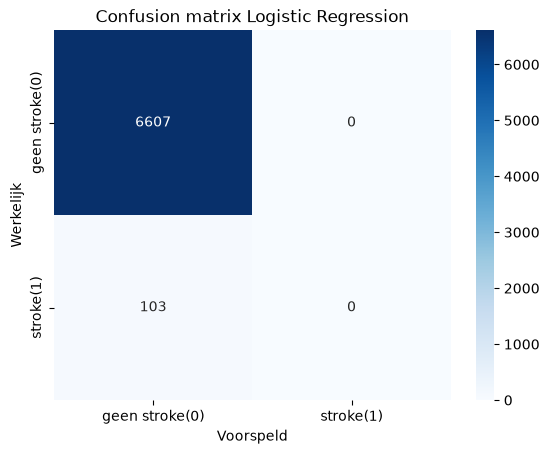

In [48]:
def confusion_matrix_heatmap(cm, titel):
    """deze functie maakt confusion matrix als heatmap met de aantallen erin"""
    labels = ["geen stroke(0)", "stroke(1)"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels) # we kiezen blauwe kleur om onze visualisatie duidelijker aan te tonen.
    plt.xlabel("Voorspeld")
    plt.ylabel("Werkelijk")
    plt.title(titel)
    plt.show()

# hier confusion matrix van 2.1 laten zien
cm = confusion_matrix(y_test, y_pred)

# die vier getallen uit matrix halen en de volgorde gaat zo : (TN, FP, FN, TP)
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives: {tn}, False Positives: {fp}, False Negatives: {fn}, True Positives: {tp}")

confusion_matrix_heatmap(cm, "Confusion matrix Logistic Regression")

In de testset zitten 6710 patienten, waarvan 103 met een stroke. Het model voorspelt bij niemand een stroke: TP en FP zijn allebei 0. Alle 103 stroke-patienten worden dus gemist (FN = 103) en dit komt doordat stroke zo weinig voorkomt. Het model voorspelt een patient pas als stroke als de kans hoger is dan 0,5 en dat gebeurt bij geen enkele patient en dit tonen we straks in deze notebook.

### 2.2.2 Hoe wordt iedere metric berekend?


Hieronder staat per metric wat hij meet, de formule en de berekening met de getallen van ons model.

**Accuracy** is het deel van alle voorspellingen dat goed is.

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

Ons model: (0 + 6607) / 6710 = 0,985.

**Precision** geeft aan welk deel van de patienten die het model als stroke voorspelt ook echt een stroke heeft. Het zegt dus hoe betrouwbaar een stroke voorspelling is.

$$\text{Precision} = \frac{TP}{TP + FP}$$

Ons model: 0 / (0 + 0). Delen door 0 kan niet, omdat het model niemand als stroke voorspelt. In `bereken_metrics` hebben we `zero_division=0` ingesteld, daarom geeft scikit-learn in dit geval 0.

**Recall** geeft aan welk deel van de patiënten die echt een stroke hebben, door het model wordt gevonden.

$$\text{Recall} = \frac{TP}{TP + FN}$$

Ons model: 0 / (0 + 103) = 0. Het model vindt geen enkele stroke-patient.

**F1-score** is het harmonisch gemiddelde van precision en recall. De F1-score is alleen hoog als precision en recall allebei hoog zijn.

$$F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

Ons model: precision en recall zijn allebei 0, dus de F1-score is ook 0.

**ROC-AUC** werkt anders. Deze metric gebruikt niet een confusion matrix maar de kansen die het model geeft. Dit leggen we uit in 2.2.4.

Om te controleren of we de formules goed begrijpen, hebben we ze zelf in een functie gezet en vergelijken we de uitkomst met `bereken_metrics` uit 2.1.




In [49]:
def metrics_met_de_hand(tn, fp, fn, tp):
    """Rekent de metrics uit met de getallen van de confusion matrix."""
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    # voorspelt het model niemand als stroke, dan is tp + fp gelijk
    # aan 0 en kunnen we niet delen: dan wordt precision 0
    if tp + fp == 0:
        precision = 0
    else:
        precision = tp / (tp + fp)

    recall = tp / (tp + fn)

    # F1 kan ook niet als precision en recall allebei 0 zijn
    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)

    return pd.Series({"Accuracy": accuracy, "Precision": precision,
                      "Recall": recall, "F1-score": f1}).round(3)


# zelf uitgerekend naast de uitkomst van scikit-learn
vergelijking = pd.DataFrame({
    "Met de hand": metrics_met_de_hand(tn, fp, fn, tp),
    "Scikit-learn": bereken_metrics(y_test, y_pred),
})
vergelijking

,Met de hand,Scikit-learn
Accuracy,0.985,0.985
Precision,0.000,0.000
Recall,0.000,0.000
F1-score,0.000,0.000


Uit onze onderzoek naar uitkomsten van Scikit-learn en "metdehand" functie hebben we waargenomen dat de uitkomsten hetzelfde zijn dus de formules kloppen. Je ziet ook goed waarom accuracy hier een slechte maatstaf is: de accuracy is 0,985, terwijl het model geen enkele stroke-patient vindt. Van de patienten in de testset heeft 98,5% geen stroke, dus als je altijd 'geen stroke' voorspelt heb je al bijna alles goed.

### 2.2.3 Een voorbeeld met een lagere drempel

Omdat ons model bij niemand een stroke voorspelt, zijn precision, recall en F1-score allemaal 0 en daardoor zie je nog niet goed hoe deze formules werken. Logistic Regression geeft voor iedere patient een kans op stroke (`predict_proba`). Standaard wordt een patient als stroke voorspeld als die kans hoger is dan 0,5 (dit heet de drempel of threshold). We kijken eerst wat de hoogste kans is die het model geeft en daarna verlagen we de drempel als voorbeeld naar 0,1: een patient wordt dan als stroke voorspeld als de kans 10% of hoger is.

Voor duidelijkheid, dit doen we alleen om de metrics beter uit te leggen. Het kiezen van een goede drempel en oplossen van de ongebalanceerde data komen later in het portfolio aan bod.

Hoogste kans op stroke: 0.27
TN: 6486  FP: 121  FN: 93  TP: 10


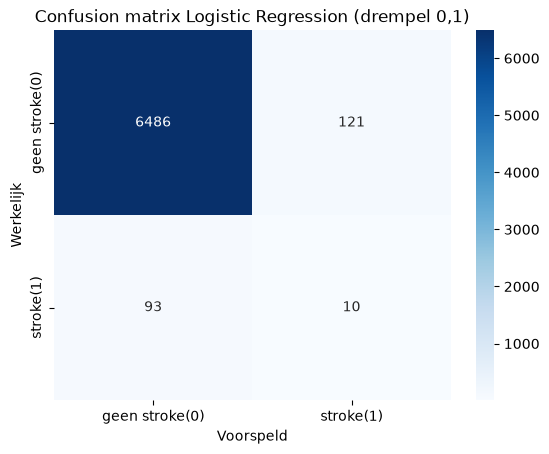

,Met de hand,Scikit-learn
Accuracy,0.968,0.968
Precision,0.076,0.076
Recall,0.097,0.097
F1-score,0.085,0.085


In [50]:
# hoogste kans op stroke die het model aan een patient geeft
print("Hoogste kans op stroke:", round(y_kans.max(), 3))

# drempel verlagen van 0,5 naar 0,1
y_pred_drempel = (y_kans >= 0.1).astype(int)

# nieuwe confusion matrix en de vier getallen
cm_drempel = confusion_matrix(y_test, y_pred_drempel)
tn2, fp2, fn2, tp2 = cm_drempel.ravel()
print("TN:", tn2, " FP:", fp2, " FN:", fn2, " TP:", tp2)

confusion_matrix_heatmap(cm_drempel,
                       "Confusion matrix Logistic Regression (drempel 0,1)")

# weer zelf uitgerekend naast scikit-learn
vergelijking_drempel = pd.DataFrame({
    "Met de hand": metrics_met_de_hand(tn2, fp2, fn2, tp2),
    "Scikit-learn": bereken_metrics(y_test, y_pred_drempel),
})
vergelijking_drempel

De hoogste kans die het model geeft is 0,27. Bij een drempel van 0,5 wordt dus niemand als stroke voorspeld. Met een drempel van 0,1 vullen we de formules in met de nieuwe confusion matrix:

- Accuracy = (10 + 6486) / 6710 = 0,968
- Precision = 10 / (10 + 121) = 0,076
- Recall = 10 / (10 + 93) = 0,097
- F1-score = 2 · 0,076 · 0,097 / (0,076 + 0,097) = 0,085

Het model vindt nu 10 van de 103 stroke-patienten. Daar staan wel 121 vals alarmen tegenover: van de 131 patienten die als stroke worden voorspeld, heeft maar 7,6% echt een stroke. De accuracy is gedaald van 0,985 naar 0,968 terwijl het model nu wel stroke-patienten vindt. Een hogere accuracy betekent hier dus niet dat het model beter is.

Ook zie je dat precision en recall tegen elkaar in werken: als je de drempel verlaagt, vind je meer stroke-patienten, maar krijg je ook meer vals alarmen.

### 2.2.4 ROC-AUC


De ROC-AUC kun je niet uit een confusion matrix halen, omdat deze metric naar alle mogelijke drempels tegelijk kijkt. Voor iedere drempel maak je een confusion matrix en bereken je twee getallen:

- **True Positive Rate (TPR)**: dit is hetzelfde als de recall: $TPR = \frac{TP}{TP + FN}$
- **False Positive Rate (FPR)**: het deel van de patiënten zonder stroke dat onterecht als stroke wordt voorspeld: $FPR = \frac{FP}{FP + TN}$

Als je voor alle drempels de FPR (x-as) tegen de TPR (y-as) zet, krijg je de ROC-curve. De ROC-AUC (Area Under the Curve) is de oppervlakte onder deze curve. Een perfect model heeft een AUC van 1 en een model dat gokt een AUC van 0,5. Dat is de diagonale lijn (Géron, 2019).

Hieronder rekenen we de TPR en FPR zelf uit voor drempels van 0 tot 1 in stappen van 0,001. Onze twee confusion matrices (drempel 0,5 en 0,1) zijn twee punten op deze curve.

Drempel 0,5: FPR = 0.0  TPR = 0.0
Drempel 0,1: FPR = 0.018  TPR = 0.097


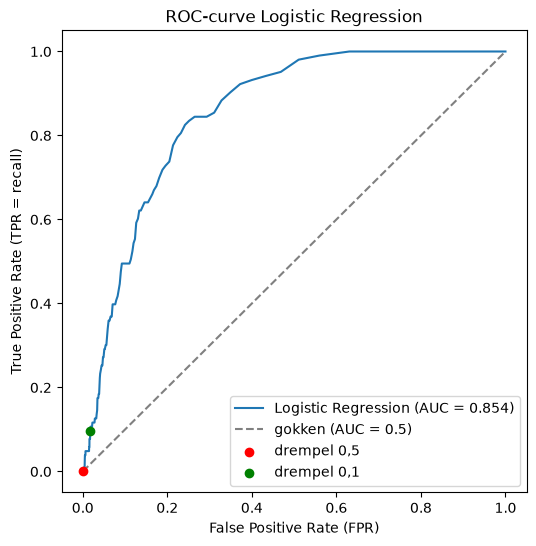

In [51]:
# drempels van 0 tot 1 in stappen van 0,001
drempels = [i / 1000 for i in range(1001)]
tpr_lijst = []
fpr_lijst = []

# per drempel een confusion matrix maken en TPR en FPR uitrekenen
for drempel in drempels:
    voorspelling = (y_kans >= drempel).astype(int)
    tn_d, fp_d, fn_d, tp_d = confusion_matrix(y_test, voorspelling).ravel()
    tpr_lijst.append(tp_d / (tp_d + fn_d))
    fpr_lijst.append(fp_d / (fp_d + tn_d))

# de twee punten van onze confusion matrices
print("Drempel 0,5: FPR =", round(fp / (fp + tn), 3),
      " TPR =", round(tp / (tp + fn), 3))
print("Drempel 0,1: FPR =", round(fp2 / (fp2 + tn2), 3),
      " TPR =", round(tp2 / (tp2 + fn2), 3))

# ROC curve tekenen, met de diagonaal (gokken) als vergelijking
auc = roc_auc_score(y_test, y_kans)
plt.figure(figsize=(6, 6))
plt.plot(fpr_lijst, tpr_lijst, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey",
         label="gokken (AUC = 0.5)")
plt.scatter(fp / (fp + tn), tp / (tp + fn), color="red", zorder=3,
            label="drempel 0,5")
plt.scatter(fp2 / (fp2 + tn2), tp2 / (tp2 + fn2), color="green", zorder=3,
            label="drempel 0,1")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR = recall)")
plt.title("ROC-curve Logistic Regression")
plt.legend()
plt.show()

[ChatGPT, 2026, Code](https://chatgpt.com/share/6ac417b9-2e90-83eb-aab0-6b4dfa55a3e3)


Oke dus bij drempel 0,5 zitten we linksonder in de hoek (FPR = 0 en TPR = 0), omdat het model niemand als stroke voorspelt en bij drempel 0,1 is de FPR 0,018 en de TPR 0,097. Hoe lager de drempel, hoe verder je over de curve naar rechtsboven gaat. Bij drempel 0 wordt iedereen als stroke voorspelt en zit je rechtsboven: de recall is dan 1, maar alle patienten zonder stroke zijn een vals alarm.

De ROC-AUC van ons model is 0,854 en je kunt dit lezen als de kans dat een willekeurige stroke-patient een hogere voorspelde kans krijgt dan een willekeurige patient zonder stroke. Het model heeft dus wel iets geleerd: stroke-patienten krijgen meestal een hogere kans. Het probleem zit vooral in de drempel van 0,5, die voor deze ongebalanceerde data veel te hoog is.

We moeten wel oppassen met de ROC-AUC bij ongebalanceerde data. De FPR wordt gedeeld door het grote aantal patienten zonder stroke (6.607) en daardoor geven 121 vals alarmen maar een FPR van 0,018 en ziet de curve er gunstig uit. Volgens Geron (2019) kun je bij een zeldzame positieve klasse daarom beter ook naar precision en recall kijken.

[Géron, 2019, Hands-On Machine Learning](https://www.scirp.org/reference/referencespapers?referenceid=3265407)


### 2.2.5 Overzicht

| Metric | Formule | Drempel 0,5 | Drempel 0,1 | Wat zegt het bij stroke? |
|---|---|---|---|---|
| Accuracy | (TP + TN) / (TP + TN + FP + FN) | 0,985 | 0,968 | Deel van alle voorspellingen dat goed is. Misleidend bij ongebalanceerde data. |
| Precision | TP / (TP + FP) | 0 | 0,076 | Hoe vaak een stroke voorspelling klopt. Laag betekent veel vals alarm. |
| Recall | TP / (TP + FN) | 0 | 0,097 | Welk deel van de stroke-patienten wordt gevonden. Laag betekent veel gemiste patienten. |
| F1-score | 2 · precision · recall / (precision + recall) | 0 | 0,085 | Combinatie van precision en recall. |
| ROC-AUC | Oppervlakte onder ROC-curve (TPR tegen FPR) | 0,854 | 0,854 | Hoe goed het model stroke en niet stroke-patienten uit elkaar houdt los van de drempel. |

Voor het voorspellen van een stroke is de recall belangrijk, omdat een gemiste stroke-patient (FN) de ergste fout is. Alleen naar recall kijken is wel te makkelijk: als je iedereen als stroke voorspelt is de recall 1, maar dan heb je niks aan het model. Daarom is de F1-score, die precision en recall combineert voor deze dataset een betere maatstaf dan accuracy.

### 2.3 Verklaring van f1-score
Om te verklaren waarom de f1-score de beste maatstaf is voor dit vraagstuk, moeten wij eerst vaststellen wat de f1-score is. De f1-score is een maatstaf die precision en recall combineert, waarbij de uitkomst altijd tussen 0 en 1 ligt. De formule voor de f1-score ziet er als volgt uit:


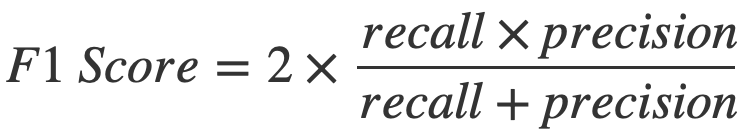

Zoals besproken in opdracht 2.1 geeft precision, in de context van dit onderzoek, aan welk deel van de patiënten die het model als 'stroke' voorspelt daadwerkelijk een stroke heeft gehad. Recall geeft aan welk deel van de patiënten die daadwerkelijk een stroke hebben gehad, ook als zodanig door het model wordt herkend. De f1-score is het harmonisch gemiddelde van deze twee metrics en is dus alleen hoog als beide hoog zijn. Een ander kenmerk van de f1-score is dat deze bruikbaar is bij sterk ongebalanceerde datasets.

Dat laatste is voor ons relevant, omdat onze dataset sterk ongebalanceerd is. Uit opdracht 1.4.1 bleek dat slechts 1,54% van alle patiënten in onze dataset daadwerkelijk een stroke heeft gehad: van de 33.550 patiënten zijn dat er ongeveer 517. Bij ongebalanceerde data geeft de accuracy een vertekend beeld. Een model dat voor iedere patiënt voorspelt dat er geen stroke komt, haalt namelijk al een accuracy van ongeveer 98,5%, terwijl het geen enkele stroke-patiënt herkent. Dat is precies wat ons model deed. In opdracht 2.1 kwam de accuracy uit op 0,985, wat op het eerste gezicht een uitstekend resultaat lijkt. Uit ons onderzoek bleek echter dat alle 103 stroke-patiënten in onze testset door het model als 'geen stroke' werden voorspeld (false negatives). Hierdoor waren de precision en recall beide 0, en dus ook de f1-score. De accuracy zei dus niets over de bruikbaarheid van het model.

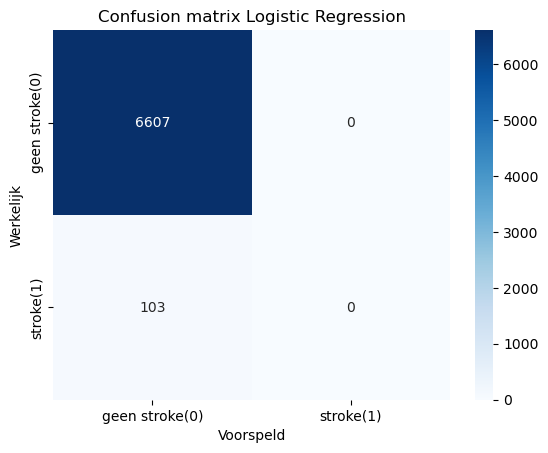 threshold/ drempel veranderen -> 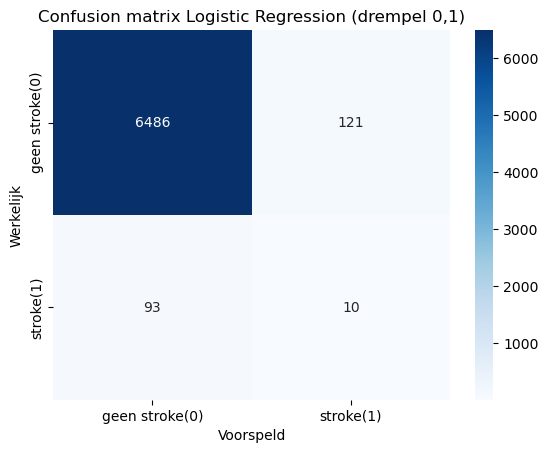

Ook precision of recall afzonderlijk zijn niet voldoende, omdat ze eenvoudig te beïnvloeden zijn. Een model dat iedere patiënt als 'stroke' voorspelt, haalt een recall van 1, maar is in de praktijk waardeloos. Een model dat slechts één patiënt als 'stroke' voorspelt en daar gelijk in heeft, haalt een precision van 1, maar mist bijna alle andere stroke-patiënten. Beide maatstaven moeten dus tegelijk goed zijn, en dat is precies wat de f1-score meet.

Daarnaast hebben in een medische context beide fouten reële gevolgen. Een gemiste stroke (false negative) is de ernstigste fout: de patiënt krijgt geen preventieve zorg of monitoring, terwijl een stroke kan leiden tot blijvende schade of overlijden. Een valse alarmering (false positive) is minder ernstig, maar niet zonder gevolgen: de patiënt ondergaat onnodig vervolgonderzoek of behandeling, wat leidt tot extra kosten, een grotere belasting van de zorg en onnodige onrust bij de patiënt. Wij willen dus geen model dat stroke-patiënten mist (recall), maar ook geen model dat te vaak ten onrechte voorspelt dat een patiënt een stroke zal krijgen (precision). De f1-score houdt met beide rekening, waardoor een model niet goed kan scoren door één van de twee fouten te negeren.

Dit zien wij ook terug in onze resultaten. Nadat wij in opdracht 2.2.3 de threshold van ons model aanpasten naar 0,1, wist het model 10 stroke-patiënten correct te voorspellen. De accuracy daalde daardoor van 0,985 naar 0,968, maar de f1-score steeg van 0 naar 0,085. De f1-score laat dus wel zien dat het model iets is gaan leren, terwijl de accuracy juist een verslechtering suggereert. De f1-score vormt echter een goed uitgangspunt, omdat deze beide fouten meeneemt. Dit is de reden waarom wij in dit vraagstuk kijken naar de f1-score en niet alleen naar de accuracy, precision of recall.

## 3 - Modelleren en uitleg modellen


### Importeren van Libraries

In [52]:
# alle nodige libraries importeren
import time
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import (StratifiedKFold, GridSearchCV,
                                     cross_val_score, cross_validate)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              GradientBoostingClassifier, VotingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

ModuleNotFoundError: No module named 'xgboost'

Hieronder staan de functies die wij gaan gebruiken bij modelleren

In [ ]:
resultaten = []   # hier verzamelen wij de resultaten van alle modellen


def oof_kansen(model, X_tr, y_tr):
    """Out-of-fold kansen: iedere patiënt krijgt een kans van een model dat hem niet heeft gezien."""
    kansen = np.zeros(len(y_tr))
    for tr, val in cv.split(X_tr, y_tr):
        m = clone(model)
        m.fit(X_tr.iloc[tr], y_tr.iloc[tr])
        kansen[val] = m.predict_proba(X_tr.iloc[val])[:, 1]
    return kansen


def kies_drempel(y_true, kansen, titel=""): 
    """Kies de drempel met de hoogste F1-score en teken F1 tegen de drempel."""
    drempels = np.arange(0.02, 0.98, 0.01)
    f1s = [f1_score(y_true, (kansen >= d).astype(int), zero_division=0) for d in drempels]
    i = int(np.argmax(f1s))
    plt.figure(figsize=(6, 3.5))
    plt.plot(drempels, f1s)
    plt.axvline(drempels[i], color="red", linestyle="--", label=f"beste drempel = {drempels[i]:.2f}")
    plt.xlabel("Drempel"); plt.ylabel("F1 (out-of-fold)"); plt.title(titel); plt.legend()
    plt.show()
    return float(drempels[i]), float(f1s[i])


def confusion_matrix_heatmap(cm, titel):
    labels = ["geen stroke(0)", "stroke(1)"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.xlabel("Voorspeld"); plt.ylabel("Werkelijk"); plt.title(titel)
    plt.show()

def evalueer(naam, model, cv_f1, params, drempel, grid_tijd, X_eval=None):
    if X_eval is None:
        X_eval = X_test
    kans = model.predict_proba(X_eval)[:, 1]
    pred_05 = (kans >= 0.5).astype(int)
    pred_dr = (kans >= drempel).astype(int)
    print(f"--- {naam} ---")
    print(f"Test-F1 bij drempel 0,50: {f1_score(y_test, pred_05, zero_division=0):.3f}")
    print(f"Test-F1 bij drempel {drempel:.2f}".replace(".", ",") + f": {f1_score(y_test, pred_dr, zero_division=0):.3f}\n")
    print(classification_report(y_test, pred_dr, digits=3, zero_division=0))
    cm = confusion_matrix(y_test, pred_dr)
    confusion_matrix_heatmap(cm, f"{naam} (drempel {drempel:.2f})")
    rapport = classification_report(y_test, pred_dr, output_dict=True, zero_division=0)["1"]
    resultaten.append({
        "Model": naam, "Beste hyperparameters": str(params), "CV-F1 (drempel 0,5)": round(cv_f1, 3),
        "Drempel": round(drempel, 2), "Test-F1 (drempel 0,5)": round(f1_score(y_test, pred_05, zero_division=0), 3),
        "Test-F1 (eigen drempel)": round(f1_score(y_test, pred_dr, zero_division=0), 3),
        "Precision": round(rapport["precision"], 3), "Recall": round(rapport["recall"], 3),
        "Tijd gridsearch (s)": round(grid_tijd, 1),
    })

### 3.1 K-Nearest Neighbors

Voor KNN en Logistic Regression gebruiken wij dezelfde patienten en dezelfde train/test-split als in opdracht 2, maar zonder de standaardisatie uit 1.4.6. In 1.4.6 schreven wij dat wij in opdracht 3 per fold standaardiseren met een `Pipeline`, zodat de scaler alleen op de trainingsdata wordt gefit en er geen data leakage is. Dat doen wij hier: de functie `maak_schaler()` standaardiseert alleen de drie numerieke kolommen dus de 0/1-kolommen blijven hetzelfde.

In [ ]:
# dezelfde patienten als in X_train en X_test (zelfde split als in 2.1),
# maar zonder de standaardisatie uit 1.4.6
X_train_ruw = df_model.loc[X_train.index].drop(columns=["stroke"])
X_test_ruw = df_model.loc[X_test.index].drop(columns=["stroke"])


def maak_schaler():
    """Standaardiseert alleen de drie numerieke kolommen (1.4.6)."""
    return ColumnTransformer(
        [("std", StandardScaler(), kolommen_standaardiseren)],
        remainder="passthrough", verbose_feature_names_out=False)


print("X_train_ruw:", X_train_ruw.shape, "| X_test_ruw:", X_test_ruw.shape)

X_train_ruw: (26840, 20) | X_test_ruw: (6710, 20)


#### 3.1.1 Hoe werkt KNN?

KNN (K-nearest Neighbors) is een eenvoudig model dat tijdens het trainen eigenlijk niets uitrekent: het onthoudt alleen alle patienten uit de trainset.

1. Het model berekent de afstand tussen de nieuwe patient en iedere patient in de trainset.
2. Het zoekt de k patienten met de kleinste afstand: de k dichtstbijzinde buren (nearest neighbors).
3. De buren stemmen. De voorspelde kans op stroke is het aandeel buren met een stroke. Zijn bijvoorbeeld 3 van de 25 buren een stroke-patient, dan is de kans 3/25 = 0,12. Ligt de kans boven de drempel, dan voorspelt het model stroke.

wie de buren zijn, hangt af van hoe je de afstand meet. De twee bekendste afstandsmaten zijn:

**Euclidean afstand**: de rechte lijn tussen twee patiënten (de stelling van Pythagoras, maar dan over alle features):

$$d_{euclidean}(a, b) = \sqrt{\sum_{j=1}^{n} (a_j - b_j)^2}$$

**Manhattan afstand**: de som van de absolute verschillen per feature. Je loopt als het ware via de rechte straten van Manhattan, in plaats van schuin over te steken:

$$d_{manhattan}(a, b) = \sum_{j=1}^{n} |a_j - b_j|$$

Hierin zijn $a$ en $b$ twee patienten en is $n$ het aantal features. In scikit-learn kies je de afstandsmaat met de hyperparameter `p`: `p=1` is Manhattan en `p=2` is Euclidean. Met de hyperparameter `weights` bepaal je hoe de buren stemmen: bij `"uniform"` telt iedere buur even zwaar, bij `"distance"` tellen buren die dichterbij liggen zwaarder mee.

Hieronder rekenen wij beide afstanden uit voor de eerste twee patiënten uit de trainset.

[ChatGPT, 2026, Vorm van de formule](https://chatgpt.com/share/6ac94a7b-24bc-83ed-af88-3fec0fa52e31)


In [ ]:
# afstand tussen de eerste twee patienten uit de trainset
patient_a = X_train_ruw.iloc[0]
patient_b = X_train_ruw.iloc[1]
verschil = patient_a - patient_b

euclidean = np.sqrt((verschil ** 2).sum())
manhattan = verschil.abs().sum()
print(f"Euclidean afstand: {euclidean:.2f}")
print(f"Manhattan afstand: {manhattan:.2f}")

# alleen de kolommen waarin de twee patienten van elkaar verschillen
verschil[verschil != 0]

Euclidean afstand: 19.46
Manhattan afstand: 29.04


age                   6.00
avg_glucose_level   -17.74
bmi                   5.30
dtype: float64

De twee patienten verschillen alleen in leeftijd (6 jaar), glucose (17,74) en BMI (5,30); alle 0/1-kolommen zijn gelijk. De Manhattan afstand telt de verschillen gewoon op: 6,00 + 17,74 + 5,30 = 29,04. De Euclidean afstand kwadrateert de verschillen eerst: $\sqrt{6{,}00^2 + 17{,}74^2 + 5{,}30^2} = 19{,}46$. Door het kwadrateren tellen grote verschillen bij Euclidean extra zwaar mee. Je ziet ook al dat glucose hier het grootste deel van de afstand bepaalt. Daarover gaat de volgende paragraaf.

**Waarom is standaardisatie belangrijk voor KNN**

KNN kijkt alleen naar afstanden. Een feature met grote getallen zorgt voor grote verschillen tussen patienten en bepaalt daardoor bijna alleen wie de buren zijn ook als die feature niet belangrijker is. Hoe groot de verschillen tussen patienten bij een feature gemiddeld zijn, zie je aan de variantie (spreiding). Hieronder berekenen wij welk deel van de totale variantie bij iedere feature hoort dus zonder en met standardisatie.

In [ ]:
# zelfde trainingsdata maar nu met de numerieke kolommen gestandaardiseerd
X_train_std = X_train_ruw.copy()
X_train_std[kolommen_standaardiseren] = StandardScaler().fit_transform(
    X_train_ruw[kolommen_standaardiseren])

# aandeel (%) van iedere feature in de totale spreiding (variantie)
aandeel = pd.DataFrame({
    "zonder standaardisatie": X_train_ruw.var() / X_train_ruw.var().sum(),
    "met standaardisatie": X_train_std.var() / X_train_std.var().sum(),
}) * 100
aandeel.round(1).sort_values("zonder standaardisatie", ascending=False)

,zonder standaardisatie,met standaardisatie
avg_glucose_level,75.8,17.6
age,21.5,17.6
bmi,2.6,17.6
hypertension,0.0,1.4
heart_disease,0.0,0.7
gender_Female,0.0,4.2
gender_Male,0.0,4.2
gender_Other,0.0,0.0
ever_married_No,0.0,4.1
ever_married_Yes,0.0,4.1


We laten twee kolommen zien zonder en met standaardisatie; zonder standaardisatie hoort 75,8% van de spreiding bij `avg_glucose_level` en 21,5% bij `age` en alle andere kolommen samen zijn goed voor nog geen 3%. Kenmerken die in de EDA juist een duidelijke relatie met stroke hadden, zoals `hypertension` en `heart_disease`, tellen bij het zoeken van de buren dus bijna niet mee. Dat komt alleen doordat glucose in grote getallen wordt gemeten (55 tot 282) en niet doordat glucose belangrijker is. Zou je leeftijd in maanden opslaan in plaats van in jaren dan bepaalt leeftijd ineens bijna de hele afstand, terwijl de informatie precies hetzelfde is.

Na standaardisatie hebben de drie numerieke kolommen dezelfde schaal gemiddelde 0 en standaarddeviatie 1 en tellen ze ieder even zwaar mee (17,6%). De uitkomst van KNN hangt dan niet meer af van de eenheid waarin een feature is gemeten en daarom staat in onze KNN pipeline een `StandardScaler`.

#### 3.1.2 Imbalanced data: twee technieken voor KNN

KNN heeft geen `class_weight`. Het model heeft geen loss functie waarin je fouten bij stroke-patienten zwaarder kunt laten wegen en we gebruiken deze twee technieken:

**Random undersampling.** In iedere trainingsfold gooien wij willekeurig patiënten zonder stroke weg, totdat de verhouding stroke : geen stroke gelijk is aan `sampling_strategy`. Bij `sampling_strategy=0.5` blijven er per stroke-patient 2 patienten zonder stroke over en daardoor zitten er tussen buren van een nieuwe patient veel meer stroke-patienten en kan het model stroke ook echt voorspellen. Wij gebruiken hiervoor de `RandomUnderSampler` uit het package imbalanced-learn (Lemaître et al., 2017). Die zit in een `Pipeline` van imbalanced-learn: alleen de trainingsdata van iedere fold wordt aangepast, de validatie en testdata blijven zoals ze zijn en het nadeel is dat wij informatie weggooien. Een voordeel is dat KNN veel sneller wordt, omdat er minder afstanden berekend hoeven te worden. De beste `sampling_strategy` zoeken wij met de gridsearch in 3.1.4.

**De drempel aanpassen** Na de gridsearch kiezen wij de drempel met de hoogste F1-score op de out-of-fold kansen van de trainset.


- [GeeksforGeeks, z.d., Handling Imbalanced Data for Classification](https://www.geeksforgeeks.org/machine-learning/handling-imbalanced-data-for-classification/)

- [Lemaître et al., 2017, Imbalanced-learn: A Python Toolbox to Tackle the Curse of Imbalanced Datasets](https://jmlr.org/papers/v18/16-365.html)

#### 3.1.3 Regularisatie bij KNN

KNN heeft geen gewichten en dus ook geen L1 of L2 regularisatie zoals Logistic Regression. Bij KNN regel je hoe complex het model is met het aantal buren **k** :

- **Kleine k** (bijvoorbeeld k = 1): de voorspelling hangt af van een of een paar patienten. Het model volgt iedere uitzondering en alle ruis in de trainingsdata en de beslisgrens wordt grillig en dit is dus **overfitting**.
- **Grote k**: het model middelt over veel buren. De beslisgrens wordt gladder en het model generaliseert beter, maar bij een te grote k kijkt het model ook naar patienten die niet meer op de nieuwe patient lijken. Dan ontstaat **underfitting**.

Een grotere k werkt dus als regularisatie. Ook `weights="distance"` speelt mee: dichtbije buren tellen dan zwaarder waardoor het model zich weer meer aanpast aan individuele patienten.

Wij laten dit zien door voor verschillende k de score op de trainingsdata te vergelijken met de score op de validatiedata (cross-validation). Hiervoor gebruiken wij de ROC-AUC, omdat die niet afhangt van de drempel (zie 2.2.4).

k = 1: train-AUC = 1.000, validatie-AUC = 0.523
k = 5: train-AUC = 0.977, validatie-AUC = 0.566
k = 25: train-AUC = 0.923, validatie-AUC = 0.708
k = 101: train-AUC = 0.880, validatie-AUC = 0.796


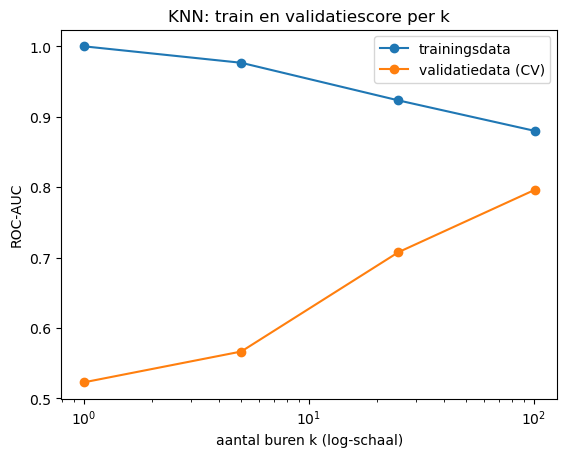

In [ ]:
# train en validatiescore voor verschillende k zonder undersampling
k_waarden = [1, 5, 25, 101]
train_auc = []
val_auc = []
# hierbij maken we een for loop
for k in k_waarden:
    knn_k = Pipeline([
        ("schalen", maak_schaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_validate(knn_k, X_train_ruw, y_train, cv=cv,
                            scoring="roc_auc", return_train_score=True,
                            n_jobs=-1)
    train_auc.append(scores["train_score"].mean())
    val_auc.append(scores["test_score"].mean())
    print(f"k = {k}: train-AUC = {train_auc[-1]:.3f}, "
          f"validatie-AUC = {val_auc[-1]:.3f}")
# hier maken we een visualisatie van onze auc
plt.plot(k_waarden, train_auc, marker="o", label="trainingsdata")
plt.plot(k_waarden, val_auc, marker="o", label="validatiedata (CV)")
plt.xscale("log")
plt.xlabel("aantal buren k (log-schaal)")
plt.ylabel("ROC-AUC")
plt.title("KNN: train en validatiescore per k")
plt.legend()
plt.show()

Bij k = 1 is de train AUC 1,000: iedere trainingspatient is zijn eigen dichtstbijzijnde buur dus het model kent de trainingsdata uit zijn hoofd en op nieuwe patienten is de AUC maar 0,523, nauwelijks beter dan gokken en dit is overfitting. Naarmate k groter wordt, daalt de train AUC en stijgt de validatie AUC (0,796 bij k = 101) en wordt het verschil tussen de twee kleiner. Een grotere k regulariseert het model dus.

#### 3.1.4 De beste hyperparameters

Met `GridSearchCV` (5-fold gestratificeerd, `scoring="f1"`, net als bij Random Forest) zoeken wij de beste combinatie van:

- `n_neighbors` (k): 25, 51, 101, 151 en 201. Uit 3.1.3 weten wij dat een kleine k overfit, daarom beginnen wij bij 25. Wij kiezen oneven getallen, zodat de stemming tussen de buren niet gelijk kan eindigen.
- `p`: 1 (Manhattan) of 2 (Euclidean).
- `weights`: `"uniform"` of `"distance"`.
- `sampling_strategy` van de undersampler: 0,25, 0,5 of 1,0.

De pipeline heeft drie stappen: standaardiseren, undersampling en knn en omdat de undersampler geen gewone scikit-learn-stap is, gebruiken wij de `Pipeline` van imbalanced-learn (`ImbPipeline`). Onder de gridsearch staat de beste CV-F1 per combinatie van k en `sampling_strategy`.

Voor onze knn gebruiken wij alleen de vier features met de duidelijkste relatie met stroke uit de EDA: `age`, `avg_glucose_level`, `hypertension` en `heart_disease`. KNN rekent afstanden over alle features en na standaardiseren bepalen de 17 dummykolommen samen bijna de helft van de afstand terwijl de meeste daarvan weinig met stroke te maken hebben (zie 1.4.4) en die kolommen maken de buren dus vooral minder relevant. Ook voegen wij `sampling_strategy` 0,1 toe aan het grid.

In [ ]:
# onze KNN gebruikt alleen de 4 belangrijkste features uit de EDA en we laten die andere kolommen droppen
# dus de andere kolommen laat de ColumnTransformer weg (remainder="drop")
knn_schaler = ColumnTransformer(
    [("std", StandardScaler(), ["age", "avg_glucose_level"]),
     ("rest", "passthrough", ["hypertension", "heart_disease"])],
    remainder="drop")

knn_pipe = ImbPipeline([
    ("schalen", knn_schaler),
    ("undersampling", RandomUnderSampler(random_state=SEED)),
    ("knn", KNeighborsClassifier()),
])
param_grid_knn = {
    "knn__n_neighbors": [25, 51, 101, 151, 201],
    "knn__p": [1, 2],
    "knn__weights": ["uniform", "distance"],
    "undersampling__sampling_strategy": [0.1, 0.25, 0.5, 1.0],
}

start = time.time()
grid_knn = GridSearchCV(knn_pipe, param_grid_knn, scoring="f1", cv=cv,
                        n_jobs=-1)
grid_knn.fit(X_train_ruw, y_train)
tijd_grid_knn = time.time() - start

print("Beste parameters:", grid_knn.best_params_)
print("Beste CV-F1:", round(grid_knn.best_score_, 3), "| tijd:",
      round(tijd_grid_knn, 1), "s")

# beste cv van F1 per combinatie van k en sampling_strategy
resultaten_knn = pd.DataFrame(grid_knn.cv_results_)
resultaten_knn.pivot_table(index="param_knn__n_neighbors",
                           columns="param_undersampling__sampling_strategy",
                           values="mean_test_score", aggfunc="max").round(3)

Beste parameters: {'knn__n_neighbors': 101, 'knn__p': 2, 'knn__weights': 'uniform', 'undersampling__sampling_strategy': 0.25}
Beste CV-F1: 0.143 | tijd: 38.6 s


param_undersampling__sampling_strategy,0.10,0.25,0.50,1.00
param_knn__n_neighbors,,,,
25,0.084,0.135,0.118,0.087
51,0.071,0.137,0.116,0.089
101,0.038,0.143,0.115,0.089
151,0.021,0.134,0.118,0.089
201,0.015,0.117,0.124,0.089


De beste combinatie is k = 101, Euclidean afstand (`p=2`), `weights="uniform"` en `sampling_strategy=0.25`, met een CV-F1 van 0,143. Met alle 20 features was dat 0,132 dus minder features helpt. In de tabel zie je dat undersampling nodig is, maar niet te ver moet gaan: bij een verhouding van 1,0 daalt de F1 naar ongeveer 0,089. Bij 0,1 is er te weinig undersampling en dan komt het aandeel stroke buren bij een grote k bijna nooit boven 0,5 en de beste waarden liggen in het midden van ons grid. De verschillen tussen de beste combinaties zijn klein (0,143, 0,137 en 0,135).

#### 3.1.5 Drempel kiezen, testset en Kaggle

Nu kiezen wij de drempel met de hoogste F1 op de out-of-fold kansen (techniek 2) en testen wij het beste model op de testset met de functie `evalueer` uit 3.0. Omdat het KNN-model zelf standaardiseert geven wij dus `X_test_ruw` mee.

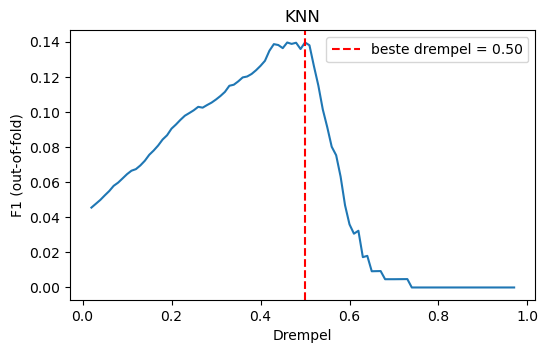

Beste drempel: 0.50 (out-of-fold F1 = 0.140)
--- KNN ---
Test-F1 bij drempel 0,50: 0.107
Test-F1 bij drempel 0,50: 0.107

              precision    recall  f1-score   support

           0      0.987     0.975     0.981      6607
           1      0.084     0.146     0.107       103

    accuracy                          0.963      6710
   macro avg      0.535     0.560     0.544      6710
weighted avg      0.973     0.963     0.967      6710



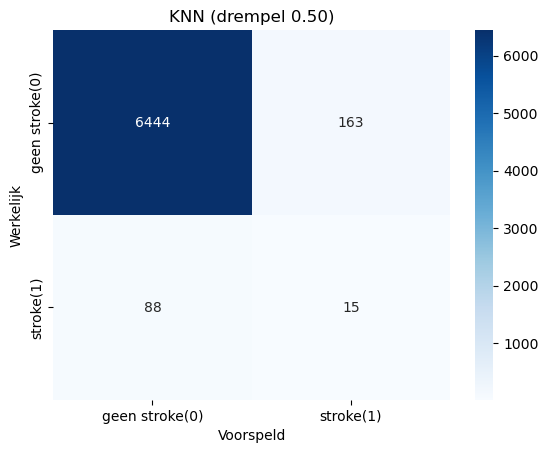

In [ ]:
# techniek 2: drempel kiezen op de out-of-fold kansen van de trainset
kansen_knn = oof_kansen(grid_knn.best_estimator_, X_train_ruw, y_train)
drempel_knn, f1_oof_knn = kies_drempel(y_train, kansen_knn, "KNN")
print(f"Beste drempel: {drempel_knn:.2f} "
      f"(out-of-fold F1 = {f1_oof_knn:.3f})")

evalueer("KNN", grid_knn.best_estimator_, grid_knn.best_score_,
         grid_knn.best_params_, drempel_knn, tijd_grid_knn,
         X_eval=X_test_ruw)

De beste drempel is precies 0,5. De undersampling heeft de kansen al genoeg verschoven: na het undersamplen is 1 op de 5 patienten in de trainingsdata een stroke-patient en op de testset haalt KNN een F1 van 0,107 (precision 0,084 en recall 0,146) dus het model vindt 15 van de 103 stroke-patienten. Met alle 20 features was de test-F1 0,100. Het verschil is klein; met maar 103 stroke-patienten in de testset kan dat ook toeval zijn.

### 3.2 Logistic Regression

#### 3.2.1 Hoe werkt Logistic Regression?

Logistic Regression is een model voor classificatie dat voor iedere patient een kans tussen 0 en 1 voorspelt. Eerst berekent het model een gewogen som van de features net als bij lineaire regressie:

$$z = b + w_1 x_1 + w_2 x_2 + \dots + w_n x_n$$

Hierin zijn $x_1$ tot en met $x_n$ de features van een patiënt, $w_1$ tot en met $w_n$ de gewichten (coëfficiënten) en is $b$ de intercept. De uitkomst $z$ kan ieder getal zijn. De **sigmoid-functie** zet $z$ om naar een kans:

$$p = \sigma(z) = \frac{1}{1 + e^{-z}}$$

Een grote positieve $z$ geeft een kans dicht bij 1, een grote negatieve $z$ een kans dicht bij 0, en $z = 0$ geeft precies 0,5. Is de kans hoger dan de drempel (standaard 0,5), dan voorspelt het model stroke. Een positief gewicht betekent dat een hogere waarde van die feature de kans op stroke verhoogt dus een negatief gewicht verlaagt de kans.

Tijdens het trainen zoekt het model de gewichten en de intercept waarbij de voorspelde kansen zo goed mogelijk passen bij de echte uitkomsten. Hoe goed ze passen, meet de loss functie.

[ChatGPT, 2026, vorm van Logistic Regression in markdown](https://chatgpt.com/share/6acae7fe-ee38-83ed-8467-ae0368aff622)


#### 3.2.2 De loss functie

Logistic Regression gebruikt de log loss ook wel binary cross entropy:

$$J(w, b) = -\frac{1}{m}\sum_{i=1}^{m}\left[y_i \log(p_i) + (1 - y_i)\log(1 - p_i)\right]$$

- $m$ is het aantal patienten, $y_i$ het echte label van patient $i$ (0 of 1) en $p_i$ de voorspelde kans op stroke.
- Heeft een patient een stroke ($y_i = 1$), dan valt het tweede deel weg en blijft $-\log(p_i)$ over. Hoe kleiner de voorspelde kans, hoe groter de loss: bij $p_i = 0{,}9$ is de loss 0,105, bij $p_i = 0{,}1$ is de loss 2,303.
- Heeft een patient geen stroke ($y_i = 0$), dan blijft $-\log(1 - p_i)$ over. Nu wordt juist een hoge kans op stroke bestraft.
- Het minteken zorgt ervoor dat de loss positief is, want de logaritme van een kans is negatief en door gemiddelde over alle patienten te nemen krijg je een getal: hoe lager, hoe beter.

met class weights wordt de loss van iedere patient vermenigvuldigd met het gewicht van zijn klasse. Een stroke-patient telt dan ongeveer 64 keer zo zwaar mee als een patient zonder stroke (32,415 tegenover 0,508) zodat het model de stroke-patienten niet meer kan negeren.

[ChatGPT, 2026, Formulevorm](https://chatgpt.com/share/6acaf708-5008-83eb-9f93-6b8739f1142d)


#### 3.2.3 Gradient descent

Voor de log loss bestaat geen formule waarmee je beste gewichten in een keer kunt uitrekene en daarom zoek je ze stap voor stap met gradient descent en je begint met startwaarden (bijvoorbeeld alle gewichten 0) en berekent de gradient: de afgeleide van de loss naar ieder gewicht. De gradient wijst in de richting waarin de loss het hardst stijgt dus zet je een kleine stap in de tegenovergestelde richting. Dat herhaal je tot de loss niet meer daalt. Hoe groot de stap is bepaal je met de learning rate $\alpha$.

Voor de log loss zijn de afgeleiden:

$$\frac{\partial J}{\partial w_j} = \frac{1}{m}\sum_{i=1}^{m}(p_i - y_i)\,x_{ij} \qquad \frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m}(p_i - y_i)$$

En de update regel is:

$$w_j := w_j - \alpha \frac{\partial J}{\partial w_j} \qquad b := b - \alpha \frac{\partial J}{\partial b}$$

**Rekenvoorbeeld.** Wij nemen 5 patienten met een feature: de gestandaardiseerde leeftijd $x$ = [−2, −1, 0, 1, 2] en stroke $y$ = [0, 0, 1, 0, 1]. Wij starten met $w = 0$, $b = 0$ en learning rate $\alpha = 0{,}5$.

*Stap 1: kansen en loss.* Alle $z = 0$, dus iedere $p_i = \sigma(0) = 0{,}5$. De loss is $-\log(0{,}5) = 0{,}693$.

*Stap 2: gradient.* De verschillen $p_i - y_i$ zijn [0,5; 0,5; −0,5; 0,5; −0,5]. Dan is:

$$\frac{\partial J}{\partial w} = \frac{1}{5}\left[0{,}5 \cdot (-2) + 0{,}5 \cdot (-1) + (-0{,}5) \cdot 0 + 0{,}5 \cdot 1 + (-0{,}5) \cdot 2\right] = \frac{-2}{5} = -0{,}4$$

$$\frac{\partial J}{\partial b} = \frac{1}{5}(0{,}5 + 0{,}5 - 0{,}5 + 0{,}5 - 0{,}5) = 0{,}1$$

*Stap 3: update.* $w = 0 - 0{,}5 \cdot (-0{,}4) = 0{,}2$ en $b = 0 - 0{,}5 \cdot 0{,}1 = -0{,}05$.

De gradient voor $w$ is negatief dus $w$ wordt groter: het model leert dat een hogere leeftijd samengaat met stroke en in de code hieronder herhalen wij deze stappen 1000 keer.

[Gemini, 2026, Referentiegesprek](https://share.gemini.google/vGf9emQ6w3pb)

In [ ]:
# we maken hier functie van sigmoid
def sigmoid(z):
    """Zet een getal z om naar een kans tussen 0 en 1."""
    return 1 / (1 + np.exp(-z))


# rekenvoorbeeld: 5 patienten 1 feature (gestandaardiseerde leeftijd)
x_vb = np.array([-2, -1, 0, 1, 2])
y_vb = np.array([0, 0, 1, 0, 1])
w, b = 0.0, 0.0   # startwaarden
alpha = 0.5       # learning rate

for stap in range(1, 1001):
    p = sigmoid(w * x_vb + b)
    loss = -np.mean(y_vb * np.log(p) + (1 - y_vb) * np.log(1 - p))
    dw = np.mean((p - y_vb) * x_vb)   # afgeleide van de loss naar w
    db = np.mean(p - y_vb)            # afgeleide van de loss naar b
    if stap <= 5 or stap == 1000:
        print(f"stap {stap}: loss = {loss:.4f}, dw = {dw:.4f}, "
              f"db = {db:.4f}")
    w = w - alpha * dw
    b = b - alpha * db

print(f"\nNa 1000 stappen: w = {w:.3f}, b = {b:.3f}")

# ter controle: scikit learn (C = 1e6, dus vrijwel geen regularisatie)
lr_vb = LogisticRegression(C=1e6).fit(x_vb.reshape(-1, 1), y_vb)
print(f"scikit-learn:    w = {lr_vb.coef_[0][0]:.3f}, "
      f"b = {lr_vb.intercept_[0]:.3f}")

stap 1: loss = 0.6931, dw = -0.4000, db = 0.1000
stap 2: loss = 0.6184, dw = -0.3012, db = 0.0877
stap 3: loss = 0.5748, dw = -0.2309, db = 0.0779
stap 4: loss = 0.5482, dw = -0.1810, db = 0.0700
stap 5: loss = 0.5311, dw = -0.1450, db = 0.0636
stap 1000: loss = 0.4844, dw = -0.0000, db = 0.0000

Na 1000 stappen: w = 1.090, b = -0.623
scikit-learn:    w = 1.090, b = -0.623


We zien dat de loss daalt van 0,6931 bij stap 1 naar 0,4844 bij stap 1000 en de gradients worden steeds kleiner tot ze bijna 0 zijn dan is het minimum bereikt en na 1000 stappen is $w = 1{,}090$ en $b = -0{,}623$, precies dezelfde waarden die scikit-learn vindt. Scikit-learn gebruikt dus een slimmere en snellere optimalisatiemethode standaard `lbfgs`maar het idee is hetzelfde dus met de afgeleiden van de loss stap voor stap de gewichten verbeteren.

#### 3.2.4 Vormen van regularisatie

Regularisatie voegt een strafterm toe aan de loss. Daardoor worden grote gewichten "duur" en houdt het model de gewichten klein en bij Logistic Regression gebruiken wij twee vormen:

**L2-regularisatie (Ridge):**

$$J_{L2}(w, b) = J(w, b) + \frac{\lambda}{2} \sum_{j=1}^{n} w_j^2$$

De straf is het kwadraat van ieder gewicht. Grote gewichten worden extra zwaar bestraft, dus alle gewichten worden kleiner. Ze worden wel bijna nooit precies 0. Dit is de standaard in scikit-learn.

**L1-regularisatie (Lasso):**

$$J_{L1}(w, b) = J(w, b) + \lambda \sum_{j=1}^{n} |w_j|$$

De straf is de absolute waarde van ieder gewicht en hierdoor worden de gewichten van minder belangrijke features precies 0. L1 doet dus ook aan feature selectie.

Hoe sterk de straf is, bepaal je met $\lambda$. In scikit-learn stel je de sterkte in met `C`, het omgekeerde van $\lambda$: een **kleine C** betekent **sterke** regularisatie. De vorm kies je met `l1_ratio`: 0 is L2 en 1 is L1.

Om het effect te laten zien, trainen wij Logistic Regression met sterke regularisatie (C = 0,01) een keer met L2 en een keer met L1 en vergelijken wij de gewichten.

refrentie van formule: ........

In [ ]:
# coefficienten bij sterke regularisatie (C = 0,01): L2 tegenover L1
coefs = {}
for naam, ratio in [("L2", 0), ("L1", 1)]:
    lr_reg = Pipeline([
        ("schalen", maak_schaler()),
        ("model", LogisticRegression(solver="liblinear", l1_ratio=ratio,
                                     C=0.01, class_weight="balanced")),
    ])
    lr_reg.fit(X_train_ruw, y_train)
    coefs[naam] = lr_reg.named_steps["model"].coef_[0]

namen = lr_reg.named_steps["schalen"].get_feature_names_out()
coef_tabel = pd.DataFrame(coefs, index=namen).round(3)
print("aantal coefficienten dat precies 0 is:")
print((coef_tabel == 0).sum())
coef_tabel

aantal coefficienten dat precies 0 is:
L2     0
L1    12
dtype: int64


,L2,L1
age,1.613,1.654
avg_glucose_level,0.184,0.180
bmi,0.045,0.018
hypertension,0.435,0.347
heart_disease,0.435,0.284
gender_Female,-0.343,-0.159
gender_Male,-0.167,0.000
gender_Other,-0.003,0.000
ever_married_No,-0.257,0.000
ever_married_Yes,-0.256,0.000


We zien hier dat met L2 is geen enkel gewicht 0 want alle gewichten zijn alleen kleiner gemaakt. Met L1 zijn 12 van de 20 gewichten precies 0. L1 houdt 8 gewichten over met de grootste voor `age`, `hypertension`, `heart_disease` en `avg_glucose_level`. Dat zijn ook de kenmerken die in onze EDA een duidelijke relatie met stroke hadden en kenmerken waarvan wij in 1.4.3 zagen dat ze vooral met leeftijd samenhangen zoals `ever_married` en `work_type`, krijgen bij L1 een gewicht van 0. Van de dubbele dummyparen (zoals `gender_Female` en `gender_Male`) houdt L1 er hooguit een over.

#### 3.2.5 Regularisatie en overfitting

Overfitting betekent dat een model de trainingsdata inclusief ruis en toevalligheden te precies leert. Het scoort dan goed op de trainingsdata, maar slechter op nieuwe pati3nten. Bij Logistic Regression gebeurt dat als de gewichten heel groot worden zodat het model zich aan individuele patienten aanpast. Regularisatie houdt de gewichten klein en maakt het model eenvoudiger waardoor de kans op overfitting kleiner wordt en te veel regularisatie (een heel kleine C) maakt het model juist te eenvoudig dan kan het ook de echte patronen niet meer leren en dat heet underfitting. De beste C ligt daartussen en die zoeken wij met cross validation.

Hieronder vergelijken wij voor verschillende C de F1-score op de trainingsdata met die op de validatiedata (L2, met class weights).

/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.lo

C = 0.0001: train-F1 = 0.069, validatie-F1 = 0.069


/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.lo

C = 0.001: train-F1 = 0.084, validatie-F1 = 0.083
C = 0.01: train-F1 = 0.090, validatie-F1 = 0.088


/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.lo

C = 0.1: train-F1 = 0.091, validatie-F1 = 0.089


/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.lo

C = 1: train-F1 = 0.091, validatie-F1 = 0.089
C = 10: train-F1 = 0.091, validatie-F1 = 0.089


/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.lo

C = 100: train-F1 = 0.091, validatie-F1 = 0.089


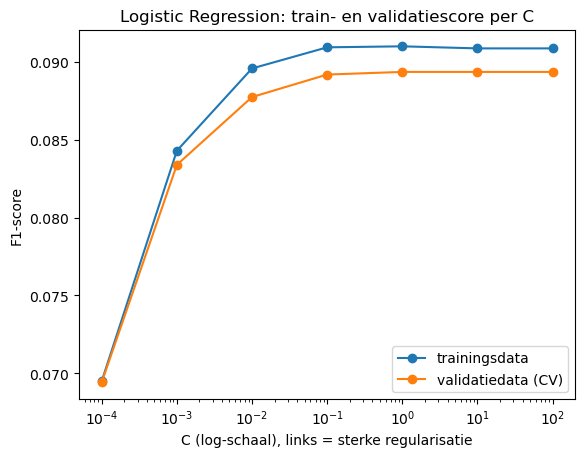

In [ ]:
# train en validatiescore (F1) voor verschillende C, met L2
C_waarden = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
train_f1 = []
val_f1 = []

for c in C_waarden:
    lr_c = Pipeline([
        ("schalen", maak_schaler()),
        ("model", LogisticRegression(solver="liblinear", C=c,
                                     class_weight="balanced")),
    ])
    scores = cross_validate(lr_c, X_train_ruw, y_train, cv=cv,
                            scoring="f1", return_train_score=True,
                            n_jobs=-1)
    train_f1.append(scores["train_score"].mean())
    val_f1.append(scores["test_score"].mean())
    print(f"C = {c}: train-F1 = {train_f1[-1]:.3f}, "
          f"validatie-F1 = {val_f1[-1]:.3f}")

plt.plot(C_waarden, train_f1, marker="o", label="trainingsdata")
plt.plot(C_waarden, val_f1, marker="o", label="validatiedata (CV)")
plt.xscale("log")
plt.xlabel("C (log-schaal), links = sterke regularisatie")
plt.ylabel("F1-score")
plt.title("Logistic Regression: train- en validatiescore per C")
plt.legend()
plt.show()

Dus bij de sterkste regularisatie (C = 0,0001) is de F1 op train en validatiedata allebei laag (0,069) dus het model is te eenvoudig en underfit. Vanaf C = 0,1 blijft de score gelijk (train 0,091 en validatie 0,089). Het verschil tussen train en validatie is bij iedere C heel klein dus Logistic Regression overfit bij onze data nauwelijks. Dat komt doordat wij veel patienten hebben (26.840 in de trainset) en maar 20 features. Regularisatie is bij deze data dus niet nodig tegen overfitting maar te veel regularisatie zorgt wel voor underfitting.

#### 3.2.6 Imbalanced data: twee technieken voor Logistic Regression

Bij Logistic Regression kunnen wij beide technieken uit 3.1.2 van KNN gebruiken gebruiken:

- **Class weights** (`class_weight="balanced"`): de loss van stroke-patienten telt zwaarder mee.
- **De drempel aanpassen** op de out-of-fold kansen van de trainset.

Eerst laten wij zien wat class weights doen door Logistic Regression zonder en met class weights te vergelijken met cross-validation.

In [ ]:
# techniek 1: zonder en met class weights (CV-F1 bij drempel 0,5)
for gewicht in [None, "balanced"]:
    lr_cw = Pipeline([
        ("schalen", maak_schaler()),
        ("model", LogisticRegression(class_weight=gewicht, max_iter=1000)),
    ])
    scores = cross_val_score(lr_cw, X_train_ruw, y_train, cv=cv,
                             scoring="f1", n_jobs=-1)
    print(f"class_weight = {gewicht}: CV-F1 = {scores.mean():.3f}")

class_weight = None: CV-F1 = 0.000
class_weight = balanced: CV-F1 = 0.089


/Users/ab/.local/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/ab/.local/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/ab/.local/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/ab/.local/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/ab/.local/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/ab/.local/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWa

Zonder class weights is de CV-F1 0,000: net als in opdracht 2 voorspelt het model bij niemand een stroke. Met class weights stijgt de CV-F1 naar 0,089. In de rest van de Logistiche Regressie gebruiken wij daarom altijd `class_weight="balanced"`.

#### 3.2.7 De beste hyperparameters met tunen

Wij tunen met `GridSearchCV` (5-fold gestratificeerd, `scoring="f1"`):

- `l1_ratio`: 0 (L2) of 1 (L1);
- `C`: 0,001, 0,01, 0,1, 1 en 10.

Wij gebruiken de solver `liblinear`, die zowel L1 als L2 ondersteunt, met `max_iter=1000` zodat het model genoeg stappen heeft om te convergeren.

In [ ]:
lr_pipe = Pipeline([
    ("schalen", maak_schaler()),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000,
                                 class_weight="balanced")),
])
param_grid_lr = {
    "model__l1_ratio": [0, 1],   # 0 = L2, 1 = L1
    "model__C": [0.001, 0.01, 0.1, 1, 10],
}

start = time.time()
grid_lr = GridSearchCV(lr_pipe, param_grid_lr, scoring="f1", cv=cv,
                       n_jobs=-1)
grid_lr.fit(X_train_ruw, y_train)
tijd_grid_lr = time.time() - start

print("Beste parameters:", grid_lr.best_params_)
print("Beste CV-F1:", round(grid_lr.best_score_, 3), "| tijd:",
      round(tijd_grid_lr, 1), "s")

# CV-F1 per C, voor L2 (l1_ratio = 0) en L1 (l1_ratio = 1)
resultaten_lr = pd.DataFrame(grid_lr.cv_results_)
resultaten_lr.pivot_table(index="param_model__C",
                          columns="param_model__l1_ratio",
                          values="mean_test_score").round(3)

/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.lo

Beste parameters: {'model__C': 1, 'model__l1_ratio': 0}
Beste CV-F1: 0.089 | tijd: 12.4 s


/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


param_model__l1_ratio,0,1
param_model__C,,
0.001,0.083,0.072
0.010,0.088,0.087
0.100,0.089,0.089
1.000,0.089,0.089
10.000,0.089,0.089


#### 3.2.8 Drempel, testset en Kaggle

Net als bij KNN kiezen wij de drempel op de out-of-fold kansen (techniek 2) en zo testen wij het beste model op de testset en maken wij het bestand voor Kaggle.

/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.lo

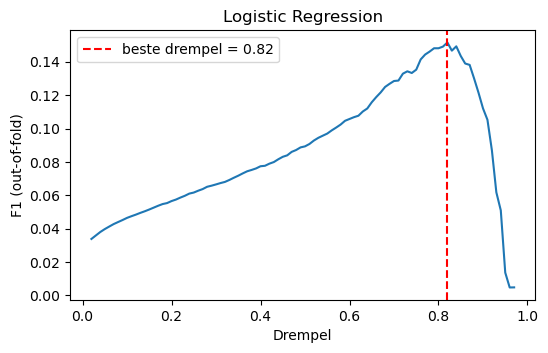

Beste drempel: 0.82 (out-of-fold F1 = 0.152)
--- Logistic Regression ---
Test-F1 bij drempel 0,50: 0.093
Test-F1 bij drempel 0,82: 0.126

              precision    recall  f1-score   support

           0      0.989     0.946     0.967      6607
           1      0.079     0.301     0.126       103

    accuracy                          0.936      6710
   macro avg      0.534     0.623     0.546      6710
weighted avg      0.975     0.936     0.954      6710



/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


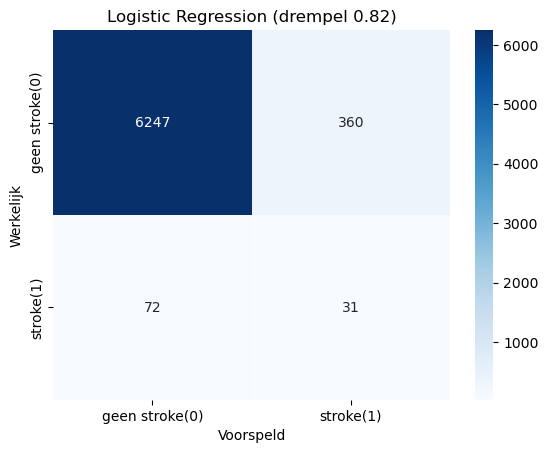

Exception ignored in: <function ResourceTracker.__del__ at 0x1041a58a0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1033c98a0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1088898a0>
Traceback (most recent call last

In [ ]:
# techniek 2: drempel kiezen op de out-of-fold kansen van de trainset
kansen_lr = oof_kansen(grid_lr.best_estimator_, X_train_ruw, y_train)
drempel_lr, f1_oof_lr = kies_drempel(y_train, kansen_lr,
                                     "Logistic Regression")
print(f"Beste drempel: {drempel_lr:.2f} "
      f"(out-of-fold F1 = {f1_oof_lr:.3f})")

evalueer("Logistic Regression", grid_lr.best_estimator_,
         grid_lr.best_score_, grid_lr.best_params_, drempel_lr,
         tijd_grid_lr, X_eval=X_test_ruw)

De beste drempel is 0,82 die ligt veel hoger dan 0,5 omdat de class weights de voorspelde kansen op stroke flink verhogen en bij drempel 0,5 worden daardoor te veel patienten als stroke voorspeld. Op de testset stijgt de F1 door de nieuwe drempel van 0,093 naar 0,126 (precision 0,079 en recall 0,301). Het model vindt dus 31 van de 103 stroke-patienten in de testset. Logistic Regression scoort op de testset beter dan KNN (0,126 tegenover 0,100)

### 3.3 Support Vector Machine (SVM)

#### 3.3.1 Werking van het model

Een Support Vector Machine (SVM) is een machine-learningmodel dat wordt gebruikt voor classificatie. In dit onderzoek wordt SVM toegepast om te voorspellen of een persoon een beroerte heeft gehad (`stroke = 1`) of niet (`stroke = 0`). Het model zoekt een beslissingsgrens die de twee klassen zo goed mogelijk scheidt. Daarbij probeert SVM de marge tussen de beslissingsgrens en de dichtstbijzijnde datapunten zo groot mogelijk te maken. Deze dichtstbijzijnde datapunten worden support vectors genoemd.

Voor een lineaire SVM wordt de beslissingsfunctie beschreven door:

$$f(x)=w^Tx+b$$

Hierbij is $x$ de vector met kenmerken van een patiënt, $w$ de vector met gewichten en $b$ de bias. De beslissingsgrens ligt waar $f(x)=0$. In een eenvoudige uitleg voorspelt het model klasse 1 als $f(x)\geq 0$ en klasse 0 als $f(x)<0$. In de uiteindelijke notebook gebruiken we daarnaast voorspelde kansen en een gekozen classificatiedrempel.

#### 3.3.2 Rekenvoorbeeld met enkele waarnemingen

Onderstaande drie voorbeelden gebruiken leeftijd en gemiddelde glucosewaarde. De waarden van de patiënten zijn illustratief en de modelgewichten zijn fictief; dit is dus geen voorspelling van het daadwerkelijk getrainde model.

| Persoon | Leeftijd $x_1$ | Glucosewaarde $x_2$ | Werkelijke klasse |
|---|---:|---:|---:|
| A | 30 | 90 | 0 |
| B | 60 | 160 | 1 |
| C | 50 | 120 | 0 |

Stel dat het model de volgende beslissingsfunctie heeft geleerd:

$$f(x)=0{,}04x_1+0{,}01x_2-3$$

Voor persoon A geldt:

$$f(x)=0{,}04(30)+0{,}01(90)-3=1{,}2+0{,}9-3=-0{,}9$$

De uitkomst is kleiner dan nul, dus het model voorspelt klasse 0.

Voor persoon B geldt:

$$f(x)=0{,}04(60)+0{,}01(160)-3=2{,}4+1{,}6-3=1$$

De uitkomst is groter dan nul, dus het model voorspelt klasse 1.

Voor persoon C geldt:

$$f(x)=0{,}04(50)+0{,}01(120)-3=2+1{,}2-3=0{,}2$$

Het model voorspelt klasse 1, terwijl de werkelijke klasse in dit voorbeeld 0 is. Persoon C wordt dus verkeerd geclassificeerd. Tijdens het trainen leert SVM de gewichten en de bias uit de trainingsgegevens; ze worden in een echt model niet vooraf willekeurig gekozen.

#### 3.3.3 Kernels en de kernel trick

Een lineaire beslissingsgrens is niet altijd geschikt om de klassen te scheiden. Een kernel maakt het mogelijk om niet-lineaire patronen te modelleren. Een kernel berekent de overeenkomst tussen twee datapunten alsof deze naar een andere, mogelijk hogere-dimensionale ruimte zijn getransformeerd.

De algemene formule is:

$$K(x_i,x_j)=\phi(x_i)^T\phi(x_j)$$

Hierbij zijn $x_i$ en $x_j$ twee datapunten en is $\phi(x)$ de transformatie naar een andere ruimte. De kernelwaarde geeft de overeenkomst tussen de getransformeerde datapunten weer.

De kernel trick houdt in dat de overeenkomst rechtstreeks met de kernel wordt berekend, zonder de transformatie naar de hogere-dimensionale ruimte expliciet uit te voeren. Hierdoor kan SVM niet-lineaire grenzen leren zonder alle nieuwe kenmerken daadwerkelijk te hoeven aanmaken.

In dit notebook onderzoeken we onder andere de Radial Basis Function-kernel (RBF):

$$K(x_i,x_j)=\exp\left(-\gamma\|x_i-x_j\|^2\right)$$

Hierbij is $\|x_i-x_j\|^2$ de gekwadrateerde afstand tussen twee datapunten en bepaalt $\gamma$ hoe snel de kernelwaarde afneemt bij een grotere afstand.

Stel dat de gekwadrateerde afstand tussen twee gestandaardiseerde datapunten 2 is en $\gamma=0{,}5$. Dan geldt:

$$K(x_i,x_j)=e^{-0{,}5\cdot2}=e^{-1}\approx0{,}368$$

De kernelwaarde is ongeveer 0,368. Bij punten die dichter bij elkaar liggen, ligt de RBF-kernelwaarde dichter bij 1. Bij grotere afstanden nadert de waarde 0. Een kleine $\gamma$ geeft punten een bredere invloed; een grote $\gamma$ maakt de invloed lokaler en kan tot een grillige beslissingsgrens leiden.

#### 3.3.4 Lossfunctie

Een soft-margin SVM probeert een grote marge te vinden en tegelijkertijd classificatiefouten te beperken. De optimalisatiefunctie kan worden geschreven als:

$$\min_{w,b}\left[\frac{1}{2}\|w\|^2+C\sum_{i=1}^{n}\max(0,1-y_i(w^Tx_i+b))\right]$$

Voor deze formule worden de klasselabels weergegeven als $y_i\in\{-1,+1\}$. De parameter $C$ bepaalt hoe zwaar fouten worden bestraft ten opzichte van regularisatie.

De functie bevat twee onderdelen:

- Regularisatieterm:$\frac{1}{2}\|w\|^2$. Deze stimuleert kleinere gewichten en een grotere marge.
- Hinge loss: $L_i=\max(0,1-y_if(x_i))$, waarbij $f(x_i)=w^Tx_i+b$. Deze geeft een straf wanneer een datapunt verkeerd is geclassificeerd of niet buiten de gewenste marge ligt.

Stel dat het werkelijke label $y_i=+1$ is en het model $f(x_i)=0{,}6$ voorspelt. Dan geldt:

$$L_i=\max(0,1-(+1)(0{,}6))=0{,}4$$

Het datapunt ligt aan de juiste kant van de grens, maar nog niet buiten de gewenste marge. Daarom is de loss groter dan nul. Wanneer $f(x_i)=1{,}2$, geldt:

$$L_i=\max(0,1-1{,}2)=0$$

Het datapunt ligt dan aan de juiste kant en buiten de gewenste marge. Wanneer een positief datapunt verkeerd wordt geclassificeerd met $f(x_i)=-0{,}5$, geldt:

$$L_i=\max(0,1-(-0{,}5))=1{,}5$$

De loss is in dat geval groter, omdat het datapunt verkeerd wordt geclassificeerd.

#### 3.3.5 Regularisatie

Regularisatie helpt voorkomen dat het model te sterk reageert op individuele datapunten. De standaard soft-margin SVM gebruikt L2-regularisatie op de gewichten:

$$R(w)=\frac{1}{2}\|w\|^2=\frac{1}{2}\sum_{j=1}^{p}w_j^2$$

De gewichten worden gekwadrateerd en opgeteld. Grote gewichten leiden daardoor tot een hogere regularisatieterm. Het model wordt gestimuleerd kleinere gewichten te gebruiken, wat kan helpen om overfitting te beperken.

Bijvoorbeeld, voor $w_1=2$ en $w_2=1$ geldt:

$$R(w)=\frac{1}{2}(2^2+1^2)=2{,}5$$

Voor kleinere gewichten $w_1=1$ en $w_2=0{,}5$ geldt:

$$R(w)=\frac{1}{2}(1^2+0{,}5^2)=0{,}625$$

De tweede combinatie heeft een kleinere regularisatieterm. Dit illustreert dat L2-regularisatie grote gewichten sterker bestraft.

De parameter $C$ regelt de afweging tussen regularisatie en de foutterm:

$$\frac{1}{2}\|w\|^2+C\sum_{i=1}^{n}L_i$$

- Kleine $C$: fouten worden relatief minder zwaar bestraft en regularisatie heeft meer invloed. Dit kan overfitting verminderen, maar kan ook underfitting veroorzaken.
- Grote $C$: fouten worden relatief zwaar bestraft. Het model probeert de trainingsgegevens strenger te classificeren, maar kan gevoeliger worden voor ruis.

$C$ is dus geen afzonderlijke regularisatiemethode, maar bepaalt de afweging tussen de foutterm en regularisatie. Bij een RBF-kernel beïnvloedt ook $\gamma$ de complexiteit van de beslissingsgrens. Een hoge $\gamma$ kan leiden tot een grilligere grens, terwijl een lage $\gamma$ meestal een gladdere grens oplevert.

Daarnaast gebruikt dit notebook `class_weight="balanced"`. Dit is geen regularisatie, maar een instelling die rekening houdt met de ongelijke verdeling van de klassen. Omdat ongeveer 1,54% van de waarnemingen in deze dataset de klasse `stroke = 1` heeft, krijgen fouten bij de minderheidsklasse relatief meer gewicht. Ook wordt de classificatiedrempel met out-of-fold voorspellingen op de trainingsdata gekozen; de testset wordt hiervoor niet gebruikt.

#### 3.3.6 Hyperparameteroptimalisatie en gekozen metric

De beste hyperparameters worden bepaald met `GridSearchCV` en vijfvoudige gestratificeerde cross-validatie. De gekozen metric is de **F1-score**, die precision en recall combineert:

$$F1=2\cdot\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

Precision geeft aan welk deel van de voorspelde positieve gevallen daadwerkelijk positief is. Recall geeft aan welk deel van alle werkelijke positieve gevallen door het model wordt gevonden. De F1-score is relevant omdat de positieve klasse sterk in de minderheid is. Alleen accuracy gebruiken kan een misleidend beeld geven van de prestaties.

De onderzochte hyperparameters zijn:

| Hyperparameter | Geteste waarden | Betekenis |
|---|---|---|
| `kernel` | `linear`, `rbf` | Type beslissingsgrens |
| `C` | `0.1`, `1` | Afweging tussen regularisatie en classificatiefouten |
| `gamma` | `scale`, `0.01` | Invloedsschaal van de RBF-kernel; alleen relevant bij `rbf` |

De combinatie met de hoogste gemiddelde F1-score tijdens cross-validatie wordt geselecteerd. De resultaten worden opgevraagd met `grid_svm.best_params_` en `grid_svm.best_score_`. De beste combinatie en score kunnen pas worden ingevuld nadat de code daadwerkelijk is uitgevoerd. Deze combinatie is de beste binnen de onderzochte waarden en hoeft niet de beste combinatie buiten deze grid te zijn. Daarna wordt de beslissingsdrempel bepaald met out-of-fold voorspellingen op de trainingsdata en wordt het model op de afzonderlijke testset geëvalueerd.


In [ ]:
from sklearn.svm import SVC

# 3 stroke-patienten (oud) en 3 patienten zonder stroke (jong); twee kenmerken, gestandaardiseerd
stroke_vb = df_gestandaardiseerd[
    (df_gestandaardiseerd["stroke"] == 1) & (df_gestandaardiseerd["age"] > 0.8)
].sample(3, random_state=1)
geen_stroke_vb = df_gestandaardiseerd[
    (df_gestandaardiseerd["stroke"] == 0) & (df_gestandaardiseerd["age"] < 0.2)
].sample(3, random_state=1)

voorbeeld = pd.concat([stroke_vb, geen_stroke_vb])[["age", "avg_glucose_level", "stroke"]].round(2)
voorbeeld["y"] = np.where(voorbeeld["stroke"] == 1, 1, -1)  # SVM rekent met labels -1 en +1
display(voorbeeld)

X_vb = voorbeeld[["age", "avg_glucose_level"]].values
y_vb = voorbeeld["y"].values

# zeer grote C: (vrijwel) harde marge, dit past bij perfect scheidbare voorbeelddata
svm_vb = SVC(kernel="linear", C=1e6).fit(X_vb, y_vb)
w, b = svm_vb.coef_[0], svm_vb.intercept_[0]
steun = svm_vb.support_
print(f"Support vectors (rijen): {list(steun)}")

# Handmatig narekenen: voor elke support vector geldt y * (w1*x1 + w2*x2 + b) = 1.
# Dat zijn 3 vergelijkingen met 3 onbekenden (w1, w2, b).
A = np.column_stack([X_vb[steun], np.ones(len(steun))]) * y_vb[steun][:, None]
w1, w2, b_hand = np.linalg.solve(A, np.ones(len(steun)))
print(f"Opgelost met de 3 vergelijkingen: w = ({w1:.3f}, {w2:.3f}), b = {b_hand:.3f}")
print(f"Gevonden door sklearn:            w = ({w[0]:.3f}, {w[1]:.3f}), b = {b:.3f}")

# marge = 2 / ||w||
norm_w = np.sqrt(w[0] ** 2 + w[1] ** 2)
print(f"||w|| = {norm_w:.3f}  ->  marge = 2/||w|| = {2 / norm_w:.3f}")

# beslissingswaarde f(x) = w.x + b per patient, en y*f(x) (>= 1 betekent: juist en buiten de marge)
voorbeeld["f(x)"] = X_vb @ w + b
voorbeeld["y*f(x)"] = voorbeeld["y"] * voorbeeld["f(x)"]
display(voorbeeld.round(3))

# een nieuwe patient classificeren
nieuw = np.array([1.0, 0.0])  # gestandaardiseerde leeftijd 1.0, gemiddelde glucose
f_nieuw = nieuw @ w + b
print(f"Nieuwe patient: f(x) = {w[0]:.3f}*1.0 + {w[1]:.3f}*0.0 + ({b:.3f}) = {f_nieuw:.3f} "
      f"-> voorspelling: {'stroke' if f_nieuw > 0 else 'geen stroke'}")

,age,avg_glucose_level,stroke,y
22029,1.79,-0.52,1,1
9844,1.48,-0.71,1,1
11132,0.94,0.80,1,1
23634,-0.53,-0.57,0,-1
23419,-1.42,-0.28,0,-1
6141,-1.80,-0.78,0,-1


Support vectors (rijen): [np.int32(3), np.int32(1), np.int32(2)]
Opgelost met de 3 vergelijkingen: w = (1.020, 0.365), b = -0.251
Gevonden door sklearn:            w = (1.020, 0.365), b = -0.251
||w|| = 1.084  ->  marge = 2/||w|| = 1.845


,age,avg_glucose_level,stroke,y,f(x),y*f(x)
22029,1.79,-0.52,1,1,1.386,1.386
9844,1.48,-0.71,1,1,1.000,1.000
11132,0.94,0.80,1,1,1.000,1.000
23634,-0.53,-0.57,0,-1,-1.000,1.000
23419,-1.42,-0.28,0,-1,-1.802,1.802
6141,-1.80,-0.78,0,-1,-2.373,2.373


Nieuwe patient: f(x) = 1.020*1.0 + 0.365*0.0 + (-0.251) = 0.769 -> voorspelling: stroke


Het model vindt 3 support vectors: de patiënt zonder stroke op (−0,53; −0,57) en de twee stroke-patiënten op (1,48; −0,71) en (0,94; 0,80). Voor elke support vector geldt $y_i(\mathbf{w}^{T}\mathbf{x}_i + b) = 1$, wat drie vergelijkingen geeft met drie onbekenden ($w_1$, $w_2$, $b$):

- $-0{,}53\,w_1 - 0{,}57\,w_2 + b = -1$
- $\ \ 1{,}48\,w_1 - 0{,}71\,w_2 + b = +1$
- $\ \ 0{,}94\,w_1 + 0{,}80\,w_2 + b = +1$

De oplossing is $\mathbf{w} = (1{,}020;\ 0{,}365)$ en $b = -0{,}251$. De code lost dit stelsel zelf op met `np.linalg.solve` en komt exact uit op dezelfde waarden als `sklearn`. De beslissingsfunctie is dus

$$f(\mathbf{x}) = 1{,}020 \cdot \text{leeftijd} + 0{,}365 \cdot \text{glucose} - 0{,}251$$

De leeftijd weegt in dit voorbeeld dus ruim 2,5 keer zo zwaar als de glucose. De lengte van $\mathbf{w}$ is $\lVert\mathbf{w}\rVert = \sqrt{1{,}020^2 + 0{,}365^2} = 1{,}084$, zodat de marge $2/1{,}084 = 1{,}845$ breed is. In de tabel is $y \cdot f(\mathbf{x}) \ge 1$ voor alle punten: de 3 support vectors zitten er precies op (waarde 1,000), de andere punten liggen verder weg (1,386; 1,802 en 2,373) en spelen geen rol voor het model.

Een nieuwe patiënt met gestandaardiseerde leeftijd 1,0 en gemiddelde glucose krijgt $f = 1{,}020 \cdot 1{,}0 + 0{,}365 \cdot 0 - 0{,}251 = 0{,}769$. Dit is groter dan 0, dus de voorspelling is *stroke*, maar kleiner dan 1: de patiënt ligt binnen de marge en het model is dus niet erg zeker.

### 3.4 Decision Tree

#### 3.4.1 Werking

Een Decision Tree (beslisboom) deelt de patiënten op met een reeks ja/nee-vragen over één kenmerk tegelijk, bijvoorbeeld "is `age` ≤ 42?". Elke vraag splitst de groep in twee kleinere groepen. De boom bestaat uit een **wortelknoop** (de eerste vraag), **interne knopen** (volgende vragen) en **bladeren** (eindknopen zonder vraag). Om een patiënt te voorspellen loopt die vanaf de wortel langs de vragen naar een blad. De voorspelling is de meerderheidsklasse van de trainingspatiënten in dat blad; het aandeel stroke-patiënten in het blad is tegelijk de geschatte kans.

De boom wordt **greedy en recursief** opgebouwd (het CART-algoritme; Breiman et al., 1984). Bij elke knoop probeert het algoritme alle kenmerken $j$ en alle mogelijke drempels $t$, met links $S_L = \{\mathbf{x} : x_j \le t\}$ en rechts $S_R = \{\mathbf{x} : x_j > t\}$. Het kiest de splitsing die de groepen het zuiverst maakt (zie 3.2.2) en herhaalt dit voor beide kinderen, totdat een stopcriterium bereikt is: een zuiver blad, of een beperking zoals `max_depth` (zie 3.2.4). "Greedy" betekent dat elke stap lokaal de beste is; er is geen garantie dat de hele boom globaal optimaal is. Omdat een boom alleen op drempelwaarden splitst, is hij niet gevoelig voor de schaal van de kenmerken en is standaardisatie niet nodig (zie 1.6).

#### 3.4.2 Splitscriteria

Een splitsing is goed als de twee kinderen *zuiverder* zijn dan de ouder, dus als ze vooral uit één klasse bestaan. Zuiverheid wordt gemeten met een onzuiverheidsmaat $I(S)$, waarbij $p_k$ het aandeel van klasse $k$ in groep $S$ is. In `sklearn` zijn dit de opties van `criterion`:

**Gini-onzuiverheid** (standaard):

$$G(S) = 1 - \sum_{k} p_k^{2}$$

**Entropie** (`"entropy"` of `"log_loss"`):

$$H(S) = -\sum_{k} p_k \log_2 p_k$$

Bij twee klassen is de Gini maximaal 0,5 (bij een 50/50-verdeling) en 0 voor een zuivere groep; de entropie is maximaal 1 en ook 0 voor een zuivere groep. Na een splitsing berekenen we de gewogen onzuiverheid van de kinderen en daarmee de winst:

$$I_{\text{split}} = \frac{n_L}{n}\,I(S_L) + \frac{n_R}{n}\,I(S_R) \qquad\qquad \Delta I = I(S) - I_{\text{split}}$$

Bij entropie heet $\Delta I$ de **informatiewinst** (Quinlan, 1986). De boom kiest de combinatie van kenmerk en drempel met de grootste winst. Een derde, minder gebruikte maat is de misclassificatiefout $1 - \max_k p_k$; die is minder gevoelig voor veranderingen in de klassenverdeling en wordt daarom niet gebruikt om een boom te laten groeien (Hastie et al., 2009; scikit-learn developers, z.d.-e).

We rekenen dit hieronder uit voor 10 patiënten met één kenmerk (leeftijd in jaren), waarvan er 4 stroke hebben.

In [ ]:
# Splitsingsvoorbeeld: 10 patienten, 1 kenmerk (leeftijd in jaren), 4 met stroke en 6 zonder
s_stroke = df[df["stroke"] == 1][["age", "stroke"]].sample(4, random_state=5)
s_geen = df[df["stroke"] == 0][["age", "stroke"]].sample(6, random_state=5)
mini = pd.concat([s_stroke, s_geen]).sort_values("age").reset_index(drop=True)
display(mini.T)


def gini(labels):
    """Gini-onzuiverheid: 1 - som(p_k^2)."""
    p = np.bincount(labels, minlength=2) / len(labels)
    return 1 - np.sum(p ** 2)


def entropie(labels):
    """Entropie: -som(p_k * log2(p_k)), met 0*log(0) = 0."""
    p = np.bincount(labels, minlength=2) / len(labels)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))


leeftijd = mini["age"].values
label = mini["stroke"].values.astype(int)
print(f"Ouderknoop: Gini = {gini(label):.3f}, entropie = {entropie(label):.3f}\n")

# alle kandidaat-drempels = middelpunten tussen opeenvolgende leeftijden
uniek = np.unique(leeftijd)
drempels = (uniek[:-1] + uniek[1:]) / 2
rijen = []
for t in drempels:
    links, rechts = label[leeftijd <= t], label[leeftijd > t]
    n = len(label)
    gew_gini = len(links) / n * gini(links) + len(rechts) / n * gini(rechts)
    gew_entr = len(links) / n * entropie(links) + len(rechts) / n * entropie(rechts)
    rijen.append({"drempel (leeftijd <=)": t, "n links": len(links), "n rechts": len(rechts),
                  "Gini links": gini(links), "Gini rechts": gini(rechts),
                  "gewogen Gini": gew_gini, "Gini-winst": gini(label) - gew_gini,
                  "informatiewinst (entropie)": entropie(label) - gew_entr})
splits = pd.DataFrame(rijen)
display(splits.round(3))

beste = splits.loc[splits["gewogen Gini"].idxmin()]
print(f"\nBeste splitsing volgens Gini: leeftijd <= {beste['drempel (leeftijd <=)']:.1f} "
      f"(gewogen Gini {beste['gewogen Gini']:.3f}, winst {beste['Gini-winst']:.3f})")

# controle met sklearn: een boom van diepte 1 moet dezelfde drempel kiezen
from sklearn.tree import DecisionTreeClassifier
stomp = DecisionTreeClassifier(max_depth=1, criterion="gini").fit(mini[["age"]], mini["stroke"])
print(f"sklearn kiest drempel: leeftijd <= {stomp.tree_.threshold[0]:.1f}")

,0,1,2,3,4,5,6,7,8,9
age,19.0,19.0,22.0,30.0,32.0,52.0,76.0,77.0,78.0,82.0
stroke,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0


Ouderknoop: Gini = 0.480, entropie = 0.971



,drempel (leeftijd <=),n links,n rechts,Gini links,Gini rechts,gewogen Gini,Gini-winst,informatiewinst (entropie)
0,20.5,2,8,0.000,0.500,0.400,0.080,0.171
1,26.0,3,7,0.000,0.490,0.343,0.137,0.281
2,31.0,4,6,0.000,0.444,0.267,0.213,0.420
3,42.0,5,5,0.000,0.320,0.160,0.320,0.610
4,64.0,6,4,0.278,0.375,0.317,0.163,0.256
5,76.5,7,3,0.245,0.000,0.171,0.309,0.557
6,77.5,8,2,0.375,0.000,0.300,0.180,0.322
7,80.0,9,1,0.444,0.000,0.400,0.080,0.144



Beste splitsing volgens Gini: leeftijd <= 42.0 (gewogen Gini 0.160, winst 0.320)
sklearn kiest drempel: leeftijd <= 42.0


Van de 10 patiënten hebben er 4 stroke, dus $p = 0{,}4$ en $G = 1 - 0{,}4^2 - 0{,}6^2 = 0{,}480$ en $H = -(0{,}4\log_2 0{,}4 + 0{,}6\log_2 0{,}6) = 0{,}971$. De tabel toont voor elke kandidaat-drempel (het midden tussen twee opeenvolgende leeftijden) de onzuiverheid van beide kinderen.

De beste splitsing is `age` ≤ 42. Links staan 5 patiënten zonder stroke ($G = 0$, een zuiver blad), rechts 5 patiënten waarvan er 4 stroke hebben ($p = 0{,}8$, dus $G = 1 - 0{,}8^2 - 0{,}2^2 = 0{,}32$). De gewogen Gini is $\tfrac{5}{10}\cdot 0 + \tfrac{5}{10}\cdot 0{,}32 = 0{,}16$ en de winst $0{,}480 - 0{,}160 = 0{,}320$. Met entropie is de winst $0{,}971 - 0{,}361 = 0{,}610$, ook voor deze drempel het hoogst. Beide criteria kiezen hier dus dezelfde splitsing. De op één na beste drempel (76,5) geeft een gewogen Gini van 0,171 en is dus net minder goed. `sklearn` kiest dezelfde drempel (42), wat de handmatige berekening bevestigt.

#### 3.4.3 Hyperparameters bepalen op de gekozen metric (F1)

We gebruiken weer `GridSearchCV` met 5 gestratificeerde folds en F1 als score. We variëren het splitscriterium (`criterion`), de maximale diepte (`max_depth`), het minimaal aantal patiënten per blad (`min_samples_leaf`) en de klassegewichten (`class_weight`). `max_depth` en `min_samples_leaf` beperken de boom vooraf en zijn daarmee een vorm van pre-pruning (zie 3.2.4). Bomen hebben geen standaardisatie nodig, dus er zit geen scaler in dit model.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Pre-pruning zit in de hyperparameters: max_depth en min_samples_leaf beperken de boom vooraf.
# Een boom heeft geen standaardisatie nodig (zie 1.6), dus hier geen scaler.
boom_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 5, 20, 50, 100],
    "class_weight": [None, "balanced"],
}

start = time.time()
boom_zoek = GridSearchCV(DecisionTreeClassifier(random_state=42), boom_grid,
                         scoring="f1", n_jobs=-1)
boom_zoek.fit(X_train, y_train)
print(f"Rekentijd: {time.time() - start:.0f} seconden")
print(f"Beste hyperparameters: {boom_zoek.best_params_}")
print(f"Beste gemiddelde F1 (5-fold CV): {boom_zoek.best_score_:.3f}")

boom_resultaten = pd.DataFrame(boom_zoek.cv_results_)[
    ["param_criterion", "param_max_depth", "param_min_samples_leaf",
     "param_class_weight", "mean_test_score"]
].rename(columns=lambda k: k.replace("param_", "").replace("mean_test_score", "gem. F1 (CV)"))
display(boom_resultaten.sort_values("gem. F1 (CV)", ascending=False).head(10).round(3))

Rekentijd: 27 seconden
Beste hyperparameters: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1}
Beste gemiddelde F1 (5-fold CV): 0.088


,criterion,max_depth,min_samples_leaf,class_weight,gem. F1 (CV)
110,gini,10,1,balanced,0.088
143,entropy,6,50,balanced,0.086
111,gini,10,5,balanced,0.086
140,entropy,6,1,balanced,0.086
157,entropy,None,20,balanced,0.086
141,entropy,6,5,balanced,0.086
142,entropy,6,20,balanced,0.086
95,gini,5,1,balanced,0.086
96,gini,5,5,balanced,0.086
97,gini,5,20,balanced,0.086


 De beste combinatie is `criterion="gini"`, `max_depth=6`, `min_samples_leaf=100` en `class_weight="balanced"`, met een gemiddelde F1 van 0,088 in de cross-validation. In de top 10 hebben alle combinaties `class_weight="balanced"` en liggen de scores dicht bij elkaar (0,086 tot 0,088). De keuze voor `balanced` is dus veruit de belangrijkste; Gini versus entropie en de precieze diepte maken weinig uit. Op de testset geeft het model een hoge Recall (ongeveer 0,74: bijna driekwart van de stroke-patiënten wordt gevonden) maar een lage Precision (ongeveer 0,04: de meeste patiënten die als stroke worden gemarkeerd hebben het niet). Dat is verklaarbaar bij slechts 1,54% stroke-patiënten, en de F1 komt daardoor uit op ongeveer 0,08. Dat is laag in absolute zin: met alleen deze kenmerken is stroke moeilijk te voorspellen.

#### 3.4.4 Pruning en de relatie met underfitting en overfitting

**Wat is pruning?** Pruning (snoeien) is het verkleinen of beperken van een beslisboom om overfitting te voorkomen. Een volledig uitgegroeide boom splitst door tot elk blad zuiver is. Daardoor leert hij ook ruis en toevalligheden uit de trainingsdata: hij kan de trainingsdata perfect voorspellen, maar generaliseert slecht naar nieuwe patiënten. Er zijn twee vormen (scikit-learn developers, z.d.-e):

**1. Pre-pruning (early stopping).** De boom stopt met groeien voordat hij volledig is uitgegroeid, via hyperparameters zoals `max_depth` (maximale diepte), `min_samples_split` (minimaal aantal patiënten om een knoop te splitsen), `min_samples_leaf` (minimaal aantal patiënten per blad), `max_leaf_nodes` en `min_impurity_decrease` (een splitsing moet minstens deze winst opleveren). **Toegepast:** `max_depth` en `min_samples_leaf` zitten in het grid van 3.2.3.

**2. Post-pruning (cost-complexity pruning).** Eerst groeit de volledige boom, daarna worden takken weggesnoeid. Voor een deelboom $T$ met $|\tilde{T}|$ bladeren is de kosten-complexiteit

$$R_{\alpha}(T) = R(T) + \alpha\,|\tilde{T}|$$

waarbij $R(T)$ de (gewogen) misclassificatiefout van de bladeren is en $\alpha \ge 0$ (`ccp_alpha`) de straf per blad. Bij $\alpha = 0$ blijft de volledige boom het beste; naarmate $\alpha$ groeit wordt een kleinere boom beter, omdat elk extra blad de kosten verhoogt. Het algoritme snoeit steeds de "zwakste schakel": de tak waarvan het wegsnoeien de fout het minst verhoogt per bespaard blad (Breiman et al., 1984; scikit-learn developers, z.d.-f). **Toegepast:** we berekenen de reeks van alle $\alpha$-waarden (`cost_complexity_pruning_path`) en kiezen de $\alpha$ met de hoogste F1 in de cross-validation.

**Relatie met underfitting en overfitting.** Pruning stuurt de complexiteit van de boom en daarmee de afweging tussen bias en variantie:

- *Geen of weinig pruning* (grote boom, kleine $\alpha$): lage bias maar hoge variantie. De boom volgt de trainingsdata tot op de ruis, dus de F1 op de trainingsdata is hoog en op nieuwe data laag. Dit is **overfitting**.
- *Te sterke pruning* (kleine boom, grote $\alpha$): hoge bias. De boom is te simpel om de patronen te leren, en de F1 is zowel op de trainingsdata als op nieuwe data laag. Dit is **underfitting**.
- Het optimum ligt ertussen: de boom is net groot genoeg om echte patronen te vangen, maar klein genoeg om de ruis te negeren.

We tonen dit hieronder met een boom zonder pruning, en met cost-complexity pruning bij oplopende $\alpha$.

Zonder pruning: diepte 32, 1177 bladeren
  F1 train = 1.000, F1 test = 0.043


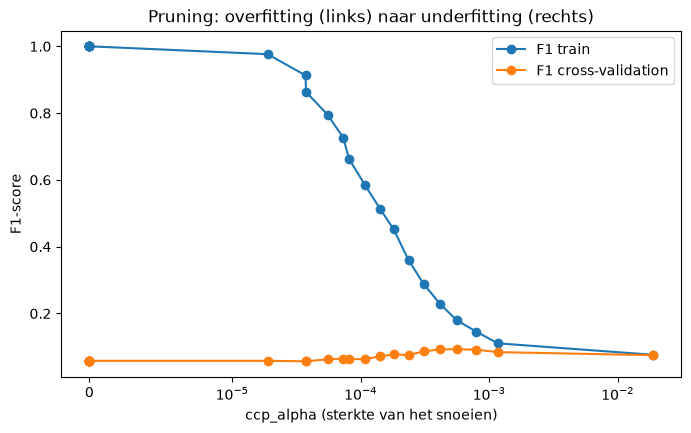

,alpha,bladeren,F1 train,F1 CV
0,0.0000,1177,1.0000,0.0582
1,0.0000,1141,1.0000,0.0582
2,0.0000,1113,1.0000,0.0582
3,0.0000,1090,1.0000,0.0582
4,0.0000,1062,1.0000,0.0582
5,0.0000,1034,1.0000,0.0582
6,0.0000,1005,1.0000,0.0582
7,0.0000,976,1.0000,0.0582
8,0.0000,947,1.0000,0.0582
9,0.0000,897,0.9764,0.0582



Beste ccp_alpha: 0.000560 (178 bladeren, F1 CV = 0.093)


In [ ]:
from sklearn.model_selection import cross_val_score

# 1) Een boom zonder enige beperking: groeit tot elk blad zuiver is (overfitting)
ongesnoeid = DecisionTreeClassifier(class_weight="balanced", random_state=42).fit(X_train, y_train)
print(f"Zonder pruning: diepte {ongesnoeid.get_depth()}, {ongesnoeid.get_n_leaves()} bladeren")
print(f"  F1 train = {f1_score(y_train, ongesnoeid.predict(X_train)):.3f}, "
      f"F1 test = {f1_score(y_test, ongesnoeid.predict(X_test)):.3f}")

# 2) Post-pruning met cost-complexity pruning: elke alpha geeft een kleinere boom
pad = ongesnoeid.cost_complexity_pruning_path(X_train, y_train)
alle_alphas = pad.ccp_alphas[:-1]  # laatste alpha = alleen de wortel
gekozen = np.unique(np.linspace(0, len(alle_alphas) - 1, 25).astype(int))
alphas = alle_alphas[gekozen]

rijen = []
for alpha in alphas:
    boom = DecisionTreeClassifier(class_weight="balanced", random_state=42, ccp_alpha=alpha)
    f1_cv = cross_val_score(boom, X_train, y_train, scoring="f1").mean()
    boom.fit(X_train, y_train)
    rijen.append({"alpha": alpha, "bladeren": boom.get_n_leaves(),
                  "F1 train": f1_score(y_train, boom.predict(X_train)), "F1 CV": f1_cv})
snoei = pd.DataFrame(rijen)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(snoei["alpha"], snoei["F1 train"], marker="o", label="F1 train")
ax.plot(snoei["alpha"], snoei["F1 CV"], marker="o", label="F1 cross-validation")
ax.set_xscale("symlog", linthresh=1e-5)
ax.set_xlabel("ccp_alpha (sterkte van het snoeien)")
ax.set_ylabel("F1-score")
ax.set_title("Pruning: overfitting (links) naar underfitting (rechts)")
ax.legend()
plt.show()
display(snoei.round(4))

beste_rij = snoei.loc[snoei["F1 CV"].idxmax()]
beste_alpha = beste_rij["alpha"]
print(f"\nBeste ccp_alpha: {beste_alpha:.6f} ({int(beste_rij['bladeren'])} bladeren, F1 CV = {beste_rij['F1 CV']:.3f})")

In [ ]:
gesnoeid = DecisionTreeClassifier(class_weight="balanced", random_state=42,
                                  ccp_alpha=beste_alpha).fit(X_train, y_train)

vergelijking = pd.DataFrame({
    "ongesnoeid": bereken_metrics(y_test, ongesnoeid.predict(X_test)),
    "pre-pruning (grid)": bereken_metrics(y_test, boom_zoek.best_estimator_.predict(X_test)),
    "post-pruning (ccp_alpha)": bereken_metrics(y_test, gesnoeid.predict(X_test)),
})
vergelijking.loc["bladeren"] = [ongesnoeid.get_n_leaves(),
                                boom_zoek.best_estimator_.get_n_leaves(),
                                gesnoeid.get_n_leaves()]
display(vergelijking)


,ongesnoeid,pre-pruning (grid),post-pruning (ccp_alpha)
Accuracy,0.973,0.820,0.846
Precision,0.047,0.044,0.047
Recall,0.039,0.515,0.466
F1-score,0.043,0.081,0.085
bladeren,1177.000,222.000,178.000


De ongesnoeide boom heeft 1.177 bladeren en een diepte van 32. Hij scoort een F1 van 1,000 op de trainingsdata maar slechts 0,042 op de testdata: een schoolvoorbeeld van overfitting. In de grafiek zie je dit links: bij $\alpha \approx 0$ is F1 train 1,0 terwijl F1 in de cross-validation slechts 0,053 is. Naarmate $\alpha$ toeneemt wordt de boom kleiner, daalt de F1 op de trainingsdata (naar 0,18 bij 178 bladeren) en stijgt de F1 in de cross-validation tot een maximum van 0,098 bij $\alpha = 0{,}00056$ (178 bladeren). Daar is de afweging tussen bias en variantie het beste. Snoeien we nog verder, dan daalt de cross-validation-score weer (0,085 bij 57 bladeren) en bij $\alpha \approx 0{,}019$ blijven er maar 2 bladeren over: F1 train en F1 CV zijn dan allebei 0,076, de boom is te simpel en onderpresteert (underfitting).

Op de testset levert beide vormen van pruning een duidelijke verbetering op ten opzichte van de ongesnoeide boom: de F1 stijgt van 0,042 naar 0,081 (pre-pruning, 41 bladeren) en 0,085 (post-pruning, 178 bladeren). Beide aanpakken geven dus vergelijkbare resultaten; de post-pruning boom heeft een iets hogere F1 en een betere Precision, de pre-pruning boom een hogere Recall. Dat de absolute F1 laag blijft (rond 0,08) komt doordat stroke met deze kenmerken moeilijk te voorspellen is bij slechts 1,54% positieve gevallen; de overige technieken tegen de klasse-onbalans volgen later.

### 3.5 Random Forest, Gradient Boosting, XGBoost en een zelfgemaakt ensemble
In dit deel passen wij drie ensembles toe op de data (Random Forest, Gradient Boosted Decision Trees en XGBoost) en bouwen wij een eigen ensemble met voting. Net als bij KNN en Logistic Regression trainen wij ook hier op `X_train_ruw`, de data die niet gestandaardiseerd is. Boommodellen zijn niet gevoelig voor de schaal van de features, dus standaardiseren is hier niet nodig. Alleen de Logistic Regression in ons eigen ensemble heeft standaardisatie wel nodig. Die zit daarom in een `Pipeline`.

In [ ]:
print("Trainset:", X_train_ruw.shape, "| stroke:", y_train.sum(), f"({y_train.mean()*100:.2f}%)")
print("Testset: ", X_test_ruw.shape, "| stroke:", y_test.sum(), f"({y_test.mean()*100:.2f}%)")

NameError: name 'X_train_ruw' is not defined

#### 3.5.1 De imbalanced dataset en onze twee technieken

**Waarom is de dataset imbalanced?** Het grootste deel van de patiënten krijgt geen stroke. De dataset geeft deze verhouding weer: slechts 517 van de 33.550 patiënten (1,54%) heeft een stroke gehad (zie 1.4.1). Een model dat leert van deze data ziet zoveel voorbeelden van 'geen stroke' dat het door altijd 'geen stroke' te voorspellen al een accuracy van ongeveer 98,5% haalt. Dat zagen wij in 2.1: accuracy 0,985, maar F1 = 0. Zonder maatregelen zijn de voorspellingen dus onbruikbaar. We kunnen dit oplossen door middel van 2 technieken. 

**Techniek 1: class weights.** Bij class weights krijgt iedere klasse een gewicht dat omgekeerd evenredig is met hoe vaak de klasse voorkomt: 

$$w_c = \frac{n}{k \cdot n_c}$$

$n$ = het aantal observaties, $k$ = het aantal klassen (2) en $n_c$ = het aantal observaties in klasse $c$. Een gemiste stroke-patiënt telt hierdoor veel zwaarder mee in de loss (of in de splitscriteria van een boom) dan een foutieve 'geen stroke'. Het model wordt dus gedwongen om ook naar de kleine groep te kijken. Er worden geen rijen toegevoegd of verwijderd, alleen het belang van de rijen verandert. Per model gebeurt dit net iets anders:

Bij **Random Forest** geldt `class_weight='balanced'`. Dat wil zeggen dat de gewichten meetellen bij het berekenen van de impurity en in de bladeren (zie opdracht 3.4). 

Bij **Gradient Boosting** bestaat er geen class_weight, maar wel `sample_weight`, daarom laten wij het model bij iedere fit zelf gebalanceerde sample weight berekenen.

Bij **XGBoost** geldt `scale_pos_weight`. Hier gaan wij de (aantal negatieven / aantal positieven) en dat vergroot de gradient van de positieve klasse.


**Techniek 2: de drempel/ threshold aanpassen.** Een model geeft een kans op stroke; standaard wordt iemand als stroke voorspeld bij een kans van 0,5 of hoger. In 2.2.3 zagen wij dat die drempel bij ongebalanceerde data te hoog is. Wij kiezen daarom per model de drempel waarbij de F1-score het hoogst is. Om te voorkomen dat wij de testset gebruiken om dit te kiezen, bepalen wij de drempel op de **out-of-fold kansen** van de trainset: bij elke fold voorspelt een model dat de betreffende patiënten nooit heeft gezien.

In [ ]:
#hint van hoe scale_pos_weight in XGBoost werkt

n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()
ratio = n_neg / n_pos                     

w_neg = len(y_train) / (2 * n_neg)
w_pos = len(y_train) / (2 * n_pos)
print(f"Gewicht geen stroke: {w_neg:.3f} | gewicht stroke: {w_pos:.3f}")
print(f"Een gemiste stroke telt dus {w_pos / w_neg:.1f}x zo zwaar mee. (scale_pos_weight = {ratio:.1f})")

Gewicht geen stroke: 0.508 | gewicht stroke: 32.415
Een gemiste stroke telt dus 63.8x zo zwaar mee. (scale_pos_weight = 63.8)


### 3.5.2 Bagging en Random Forest

**Bagging (bootstrap aggregation).** Bij bagging wordt niet één beslisboom getraind, maar meerdere. Iedere boom krijgt een eigen **bootstrap-steekproef**: een steekproef met terugleggen uit de trainset, even groot als de trainset zelf. Doordat rijen teruggelegd worden, komt een rij soms meerdere keren voor in een steekproef en soms helemaal niet (ongeveer 63% van de unieke rijen zit in een steekproef; de rest is de *out-of-bag* data). Alle bomen worden onafhankelijk van elkaar getraind. De voorspelling komt als volgt tot stand:
- **Classificatie:** iedere boom stemt op een klasse en de meerderheid wint.
- **Regressie:** de voorspelling is het gemiddelde van de voorspellingen van alle bomen.

Een enkele diepe beslisboom is gevoelig voor de trainingsdata: kleine veranderingen in de data geven een heel andere boom (hoge variantie, overfitting). Door te middelen over veel bomen die op verschillende steekproeven zijn getraind, middelen de fouten elkaar deels uit en daalt de variantie.
**Random Forest** is bagging met één extra stap: bij iedere splitsing mag een boom maar kijken naar een willekeurige subset van de features (`max_features`). Zonder deze stap zouden alle bomen vooral dezelfde sterke feature (hier `age`) bovenin gebruiken en dus sterk op elkaar lijken. Met de subset worden de bomen minder gecorreleerd, en middelen ze beter uit.

Eerst vergelijken wij een enkele boom met bagging met behulp van cross-validation, maar dan met F1 op de trainset in plaats van op de testset.

In [ ]:
#dit is een simpele boom
dt = DecisionTreeClassifier(max_depth=10, criterion="entropy", class_weight="balanced", random_state=SEED)

#dit is een ensemble van 100 bomen
bc = BaggingClassifier(estimator=dt, n_estimators=100, n_jobs=-1, random_state=SEED)

for naam, m in [("Enkele Decision Tree", dt), ("Bagging (100 bomen)", bc)]:
    scores = cross_val_score(m, X_train_ruw, y_train, cv=cv, scoring="f1", n_jobs=-1) # aangepast
    print(f"{naam}: CV-F1 = {scores.mean():.3f} (± {scores.std():.3f})")

Enkele Decision Tree: CV-F1 = 0.081 (± 0.005)
Bagging (100 bomen): CV-F1 = 0.118 (± 0.006)


##### Toelichting

Bagging scoort hoger dan de enkele beslisboom (CV-F1 0,119 tegenover 0,082). Een enkele diepe boom past zich sterk aan de trainingsdata aan, terwijl bagging de fouten van 100 bomen op verschillende bootstrap-steekproeven middelt en daardoor beter generaliseert.

### 3.5.3 Random Forest: tuning

Wij tunen met `GridSearchCV` (5-fold gestratificeerd, `scoring="f1"`). Het model gebruikt `class_weight="balanced"` (techniek 1). Wij tunen:
- `n_estimators`: aantal bomen. Meer bomen geven een stabieler resultaat, maar kosten meer tijd.
- `max_depth`: maximale diepte. Te diep geeft overfitting, te ondiep underfitting.
- `min_samples_leaf`: minimaal aantal patiënten per blad. Dit is vooral belangrijk bij ongebalanceerde data, want zonder minimum kan een boom bladeren maken voor een handjevol stroke-patiënten.

`max_features` laten wij op de standaardwaarde (`sqrt`).

Dit alles doen wij in de codecel hieronder

In [ ]:
rf = RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=1, max_features='sqrt')
param_grid_rf = {
    "n_estimators": [100, 300],
    "max_depth": [5, 8, 12],
    "min_samples_leaf": [1, 5, 10],
}

start = time.time()
grid_rf = GridSearchCV(rf, param_grid_rf, scoring="f1", cv=cv, n_jobs=-1)
grid_rf.fit(X_train_ruw, y_train)
tijd_grid_rf = time.time() - start

print("Beste parameters voor random forest:", grid_rf.best_params_)
print("Beste CV-F1:", round(grid_rf.best_score_, 3), "| tijd:", round(tijd_grid_rf, 1), "s")

Beste parameters voor random forest: {'max_depth': 12, 'min_samples_leaf': 10, 'n_estimators': 300}
Beste CV-F1: 0.129 | tijd: 60.6 s


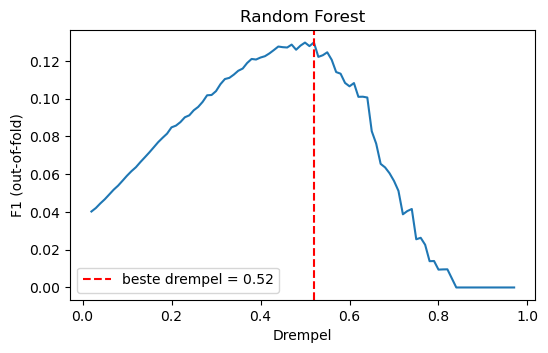

Beste drempel: 0.52 (out-of-fold F1 = 0.130)
--- Random Forest ---
Test-F1 bij drempel 0,50: 0.093
Test-F1 bij drempel 0,52: 0.092

              precision    recall  f1-score   support

           0      0.987     0.950     0.968      6607
           1      0.059     0.204     0.092       103

    accuracy                          0.938      6710
   macro avg      0.523     0.577     0.530      6710
weighted avg      0.973     0.938     0.955      6710



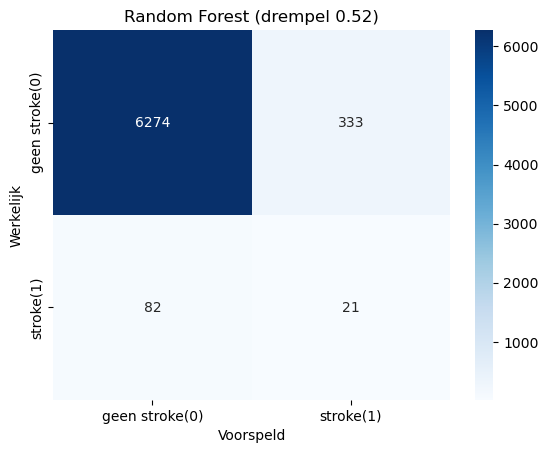

In [ ]:
# Techniek 2: drempel kiezen op out-of-fold kansen van de trainset
kansen_rf = oof_kansen(grid_rf.best_estimator_, X_train_ruw, y_train)
drempel_rf, f1_oof_rf = kies_drempel(y_train, kansen_rf, "Random Forest")
print(f"Beste drempel: {drempel_rf:.2f} (out-of-fold F1 = {f1_oof_rf:.3f})")

evalueer("Random Forest", grid_rf.best_estimator_, grid_rf.best_score_, grid_rf.best_params_, drempel_rf, tijd_grid_rf,
        X_eval = X_test_ruw)

#### Toelichting

De beste Random Forest gebruikt 300 bomen, max_depth = 12 en min_samples_leaf = 10. Door minimaal 10 patiënten per blad te eisen, worden te specifieke splitsingen beperkt en wordt overfitting tegengegaan.
De optimale out-of-fold drempel is 0,52 met een OOF-F1 van 0,130. Op de testset scoort de standaarddrempel van 0,50 echter iets beter: F1 = 0,093 tegenover 0,092 bij 0,52. Threshold tuning levert hier dus geen verbetering op.
Bij drempel 0,52 is de recall 0,204 en de precision 0,059. Random Forest herkent daarmee ongeveer 20% van de stroke-patiënten, maar maakt nog veel fout-positieve voorspellingen. De lagere test-F1 ten opzichte van de CV-F1 laat zien dat het model minder goed generaliseert naar de testset.

### 3.5.4 Gradient Boosted Decision Trees

**Boosting.** Bij boosting worden de bomen niet onafhankelijk getraind, maar **sequentieel**: elke nieuwe boom probeert de fouten van de bomen daarvoor te corrigeren. Iedere boom is een *weak learner*: een ondiepe boom die maar iets beter presteert dan gokken. Samen vormen veel weak learners een sterk model.

**AdaBoost** doet dit door na iedere boom de *wegingsfactor* van verkeerd geclassificeerde patiënten te verhogen, zodat de volgende boom daar meer op let. **Gradient boosting** doet dit via de *errors* (residuen): de volgende boom wordt getraind om de fout van het huidige model te voorspellen. Wiskundig is dit een stap in de richting van de negatieve gradient van de loss-functie $L$:



**Stochastic gradient boosting** is gradient boosting waarbij elke boom op een willekeurig deel van de rijen (`subsample < 1`) wordt getraind. Dat voegt wat ruis toe en verlaagt overfitting. Wij nemen `subsample` mee in de tuning.

**Trainingstijd.** Omdat boom $m$ pas getraind kan worden als boom $m-1$ klaar is, kunnen de bomen niet **parallel** worden getraind. Dat maakt GBDT trager dan een random forest, waarvan de bomen onafhankelijk van elkaar zijn.

`GradientBoostingClassifier` heeft geen `class_weight`. Wij gebruiken daarom `sample_weight` (techniek 1), maar laten het model die gewichten zelf berekenen op de trainingsdata van iedere fold. Zo hoeven wij geen gewichten door te geven aan `GridSearchCV`; dat zou namelijk ook de F1-score zelf met die gewichten berekenen en daardoor veel te hoge scores geven. Dit grid is klein gehouden, want gridsearch met boosting is tijdrovend.

Zie codecel hieronder

In [ ]:
class BalancedGradientBoosting(GradientBoostingClassifier):
    """GradientBoostingClassifier die sample_weight zelf berekent
    (balanced) op de y die hij in fit() krijgt."""

    def fit(self, X, y, sample_weight=None):
        sw = compute_sample_weight(class_weight="balanced", y=y)
        return super().fit(X, y, sample_weight=sw)


gb = BalancedGradientBoosting(random_state=SEED)

param_grid_gb = {
    "n_estimators": [50, 150, 300],
    "learning_rate": [ 0.1, 0.01, 0.2],
    "max_depth": [2, 3, 4],
    "subsample": [0.5, 0.6, 0.7],
}

start = time.time()
grid_gb = GridSearchCV(gb, param_grid_gb, scoring="f1", cv=cv, n_jobs=-1)
grid_gb.fit(X_train_ruw, y_train)
tijd_grid_gb = time.time() - start

print("Beste parameters voor gradient boosting:", grid_gb.best_params_)
print("Beste CV-F1:", round(grid_gb.best_score_, 3), "| tijd:", round(tijd_grid_gb, 1), "s")

Beste parameters voor gradient boosting: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300, 'subsample': 0.6}
Beste CV-F1: 0.11 | tijd: 294.0 s


Bron voor de code hierboven: [Claude: Gradient boosting classifier met sample_weight, prompt 1](https://claude.ai/share/b1339bb5-de24-414f-8090-ec74af20d409)

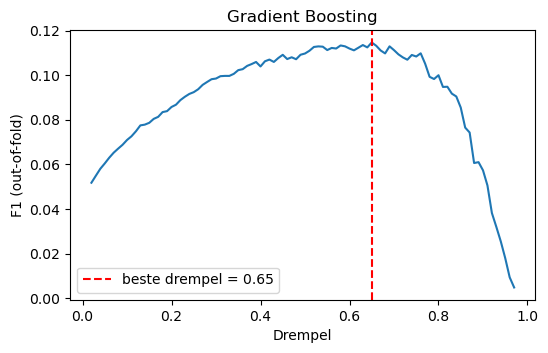

Beste drempel: 0.65 (out-of-fold F1 = 0.115)
--- Gradient Boosting ---
Test-F1 bij drempel 0,50: 0.102
Test-F1 bij drempel 0,65: 0.100

              precision    recall  f1-score   support

           0      0.987     0.950     0.968      6607
           1      0.065     0.223     0.100       103

    accuracy                          0.939      6710
   macro avg      0.526     0.587     0.534      6710
weighted avg      0.973     0.939     0.955      6710



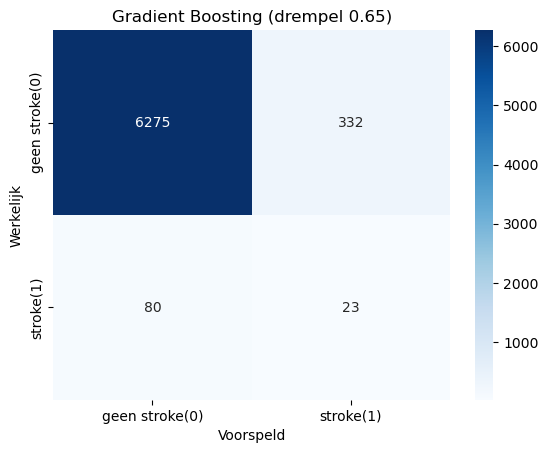

In [ ]:
kansen_gb = oof_kansen(grid_gb.best_estimator_, X_train_ruw, y_train)
drempel_gb, f1_oof_gb = kies_drempel(y_train, kansen_gb, "Gradient Boosting")
print(f"Beste drempel: {drempel_gb:.2f} (out-of-fold F1 = {f1_oof_gb:.3f})")

evalueer("Gradient Boosting", grid_gb.best_estimator_, grid_gb.best_score_, grid_gb.best_params_, drempel_gb, tijd_grid_gb,
         X_eval=X_test_ruw)

#### Toelichting

De beste GBDT-instellingen uit de GridSearch zijn learning_rate = 0.1, max_depth = 4, n_estimators = 300 en subsample = 0.6. Met deze combinatie behaalt het model een gemiddelde CV-F1 van 0,111.
De beste out-of-fold threshold is 0,65 met een OOF-F1 van 0,115. Op de testset scoort GBDT echter 0,102 bij drempel 0,50 en 0,100 bij drempel 0,65. De aangepaste threshold verbetert de testprestatie dus niet, ondanks dat deze op de trainingsdata optimaal was.

### 3.5.5 XGBoost: werking en tuning

XGBoost lijkt het meest op **gradient boosting**: ook hier worden bomen sequentieel getraind en corrigeert elke boom de fouten van de vorige (Chen & Guestrin, 2016). De belangrijkste verschillen:
- **Regularisatie in de doelfunctie.** XGBoost minimaliseert de loss plus een straf voor complexe bomen: $\text{Obj} = \sum_i l(y_i, \hat{y}_i) + \sum_k \Omega(f_k)$ met $\Omega(f) = \gamma T + \tfrac{1}{2}\lambda \sum_j w_j^2$, waarbij $T$ het aantal bladeren is en $w_j$ de bladgewichten. Dit verlaagt overfitting.
- **Tweede-orde informatie.** Naast de gradient gebruikt XGBoost ook de hessian (tweede afgeleide) om de beste splitsing en bladgewichten te berekenen.
- **Snelheid.** De bomen worden nog steeds sequentieel getraind, maar het zoeken naar de beste splitsing binnen één boom gebeurt parallel en is sterk geoptimaliseerd. Daardoor is XGBoost in de praktijk vaak sneller dan `GradientBoostingClassifier`.
- **Extra opties:** `subsample` en `colsample_bytree` (rijen en kolommen bemonsteren), `scale_pos_weight` voor imbalanced data en het automatisch omgaan met missende waarden.


In [ ]:
class BalancedXGB(XGBClassifier):
    """XGBClassifier die balanced sample_weight berekent op de y in fit()."""

    def fit(self, X, y, **kwargs):
        sw = compute_sample_weight(class_weight="balanced", y=y)
        return super().fit(X, y, sample_weight=sw, **kwargs)


xgb = BalancedXGB(
    random_state=SEED,
    eval_metric="logloss",
    n_jobs=1,  # parallelisme laten we over aan GridSearchCV
)

param_grid_xgb = {
    "n_estimators": [100, 300],
    "learning_rate": [0.03, 0.1],
    "max_depth": [3, 5],
    "subsample": [0.8, 1.0],
}

start = time.time()
grid_xgb = GridSearchCV(xgb, param_grid_xgb, scoring="f1", cv=cv, n_jobs=-1)
grid_xgb.fit(X_train_ruw, y_train)
tijd_grid_xgb = time.time() - start

print("Beste parameters voor XGBoost:", grid_xgb.best_params_)
print("Beste CV-F1 voor XGBoost:", round(grid_xgb.best_score_, 3), "| tijd:", round(tijd_grid_xgb, 1), "s")

Beste parameters voor XGBoost: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
Beste CV-F1 voor XGBoost: 0.108 | tijd: 15.9 s


Bron voor de code hierboven: [Claude: Gradient boosting classifier met sample_weight, prompt 2](https://claude.ai/share/b1339bb5-de24-414f-8090-ec74af20d409)

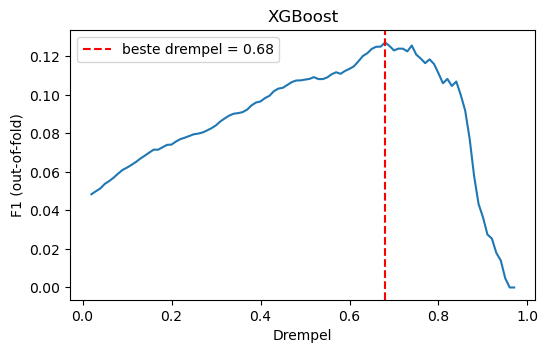

Beste drempel: 0.68 (out-of-fold F1 = 0.127)
--- XGBoost ---
Test-F1 bij drempel 0,50: 0.115
Test-F1 bij drempel 0,68: 0.126

              precision    recall  f1-score   support

           0      0.990     0.930     0.959      6607
           1      0.076     0.369     0.126       103

    accuracy                          0.922      6710
   macro avg      0.533     0.650     0.543      6710
weighted avg      0.976     0.922     0.946      6710



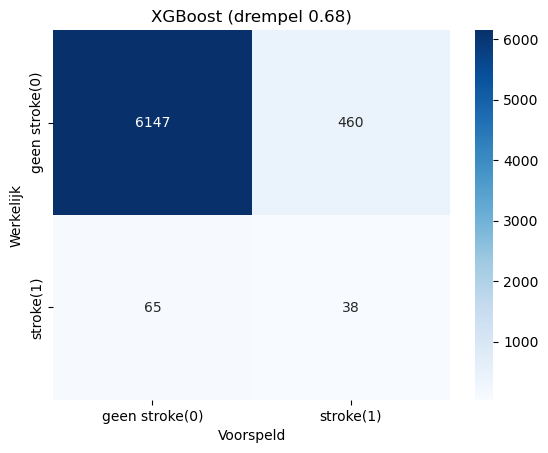

In [ ]:
kansen_xgb = oof_kansen(grid_xgb.best_estimator_, X_train_ruw, y_train)
drempel_xgb, f1_oof_xgb = kies_drempel(y_train, kansen_xgb, "XGBoost")
print(f"Beste drempel: {drempel_xgb:.2f} (out-of-fold F1 = {f1_oof_xgb:.3f})")

evalueer("XGBoost", grid_xgb.best_estimator_, grid_xgb.best_score_, grid_xgb.best_params_, drempel_xgb, tijd_grid_xgb,
         X_eval=X_test_ruw)

#### Toelichting

De beste XGBoost gebruikt 100 bomen, max_depth = 5, learning_rate = 0.1 en subsample = 0.8. Met deze instellingen behaalt het model een CV-F1 van 0,108.
De beste out-of-fold drempel is 0,68. Op de testset behaalt XGBoost bij deze drempel een F1-score van ongeveer 0,126. Het model herkent 38 van de 103 stroke-patiënten, maar voorspelt ook 460 patiënten ten onrechte als stroke. Hierdoor is de recall relatief hoger, terwijl de precision laag blijft. XGBoost presteert hiermee beter dan GBDT en had bovendien een veel kortere trainingstijd van ongeveer 15,9 seconden.

In [ ]:
schaal_kolommen = ["age", "avg_glucose_level", "bmi"]

logreg = Pipeline([
    ("prep", ColumnTransformer([("scale", StandardScaler(), schaal_kolommen)], remainder="passthrough")),
    ("lr", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
])

# Zoals in de les (Ensembles_and_XGboost 1a): een lijst met (naam, model)
classifiers = [
    ("logreg", logreg),
    ("rf",     clone(grid_rf.best_estimator_)),
    ("xgb",    clone(grid_xgb.best_estimator_)),
]

for naam, model in classifiers:
    model.fit(X_train_ruw, y_train)
    pred = model.predict(X_test_ruw)
    print(f"{naam}: test-F1 bij drempel 0,5 = {f1_score(y_test, pred):.3f}")

logreg: test-F1 bij drempel 0,5 = 0.093
rf: test-F1 bij drempel 0,5 = 0.093
xgb: test-F1 bij drempel 0,5 = 0.115


Bron: [datacamp](https://campus.datacamp.com/courses/machine-learning-with-tree-based-models-in-python/the-bias-variance-tradeoff?ex=11)


### 3.6 Eigen ensemble (voting)

Een voting-ensemble combineert de voorspellingen van meerdere verschillende modellen tot één voorspelling. Elk model maakt andere fouten, en door ze te combineren vallen die deels tegen elkaar weg. Bij hard voting stemt elk model op een klasse (0 of 1) en wint de meerderheid. Bij soft voting nemen wij het gewogen gemiddelde van de kansen van de modellen:

$$P(\text{stroke}) = \frac{\sum_m w_m \cdot p_m}{\sum_m w_m}$$

Hierbij is $p_m$ de kans van model $m$ en $w_m$ het gewicht van dat model.

Ons ensemble bestaat uit drie modellen die op een verschillende manier leren. De Logistic Regression is een lineair model en heeft standaardisatie nodig, daarom zit er een `StandardScaler` in de pipeline. De Random Forest gebruikt bagging: de bomen worden parallel getraind en kunnen niet-lineaire verbanden vinden, zoals leeftijd in combinatie met hypertensie. XGBoost gebruikt boosting: de bomen worden sequentieel getraind en corrigeren elkaars fouten. Omdat de modellen anders leren, maken ze verschillende fouten, en juist dan levert combineren het meeste op.

Van RF en XGBoost gebruiken wij de beste versies uit 3.5.3 en 3.5.5. Alle drie de modellen gebruiken class weights (techniek 1). Hieronder kijken wij eerst hoe goed elk model los scoort.

In [ ]:
vc_hard = VotingClassifier(estimators=classifiers, voting="hard")
vc_soft = VotingClassifier(estimators=classifiers, voting="soft")

for naam, vc in [("Hard voting", vc_hard), ("Soft voting", vc_soft)]:
    scores = cross_val_score(vc, X_train_ruw, y_train, cv=cv, scoring="f1", n_jobs=-1)
    print(f"{naam}: CV-F1 = {scores.mean():.3f} (± {scores.std():.3f})")

Hard voting: CV-F1 = 0.114 (± 0.011)
Soft voting: CV-F1 = 0.118 (± 0.010)


##### Hard of soft voting?

Hard voting scoort iets hoger (CV-F1 0,114 tegenover 0,118), maar dat verschil is kleiner dan de spreiding (± 0,011), dus de twee zijn eigenlijk gelijk. Wij kiezen voor **soft voting**, om twee redenen. Ten eerste geeft soft voting een kans, en die hebben wij nodig om de drempel te kiezen (techniek 2) en voor de Kaggle-submission. Hard voting geeft alleen 0 of 1. Ten tweede gebruikt soft voting ook hoe zeker een model is: een model dat 0,9 zegt, telt zwaarder mee dan een model dat 0,51 zegt.

Daarna tunen wij de gewichten van de modellen en de `C` van de Logistic Regression.

In [ ]:
param_grid_vc = {
    "weights": [[1, 1, 1], [1, 2, 2], [1, 1, 2], [1, 2, 1]],   # volgorde: logreg, rf, xgb
    "logreg__lr__C": [0.1, 1.0],
}

start = time.time()
grid_vc = GridSearchCV(vc_soft, param_grid_vc, scoring="f1", cv=cv, n_jobs=-1)
grid_vc.fit(X_train_ruw, y_train)
tijd_grid_vc = time.time() - start

print("Beste parameters voor weighted voting:", grid_vc.best_params_)
print("Beste CV-F1 voor weighted voting:", round(grid_vc.best_score_, 3), "| tijd:", round(tijd_grid_vc, 1), "s")

Beste parameters voor weighted voting: {'logreg__lr__C': 0.1, 'weights': [1, 2, 1]}
Beste CV-F1 voor weighted voting: 0.121 | tijd: 46.3 s


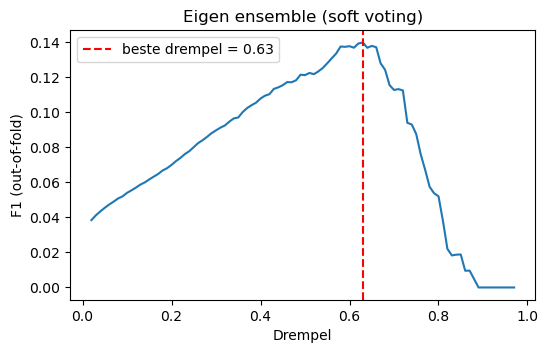

Beste drempel: 0.63 (out-of-fold F1 = 0.140)
--- Eigen ensemble (soft voting) ---
Test-F1 bij drempel 0,50: 0.123
Test-F1 bij drempel 0,63: 0.116

              precision    recall  f1-score   support

           0      0.988     0.947     0.967      6607
           1      0.074     0.272     0.116       103

    accuracy                          0.937      6710
   macro avg      0.531     0.609     0.542      6710
weighted avg      0.974     0.937     0.954      6710



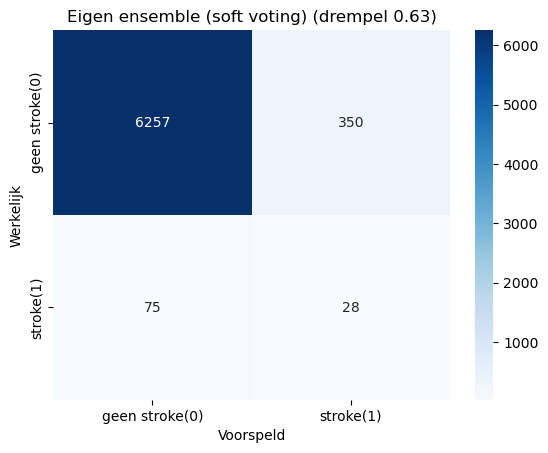

In [ ]:
kansen_vc = oof_kansen(grid_vc.best_estimator_, X_train_ruw, y_train)
drempel_vc, f1_oof_vc = kies_drempel(y_train, kansen_vc, "Eigen ensemble (soft voting)")
print(f"Beste drempel: {drempel_vc:.2f} (out-of-fold F1 = {f1_oof_vc:.3f})")

evalueer("Eigen ensemble (soft voting)", grid_vc.best_estimator_, grid_vc.best_score_, grid_vc.best_params_, drempel_vc, tijd_grid_vc,
         X_eval=X_test_ruw)

#### Toelichting

Het beste soft-voting ensemble gebruikt C = 0.1 voor Logistic Regression en de gewichten [1, 2, 1]. Hierdoor telt Random Forest twee keer zo zwaar mee als Logistic Regression en XGBoost. Met deze instellingen behaalt het ensemble een CV-F1 van 0,121.
De beste out-of-fold drempel is 0,63 met een OOF-F1 van 0,140. Op de testset scoort de standaarddrempel 0,50 echter beter: F1 = 0,123 tegenover 0,116 bij drempel 0,63. Bij drempel 0,63 herkent het ensemble 28 van de 103 stroke-patiënten, maar voorspelt het ook 350 patiënten ten onrechte als stroke. De aangepaste threshold levert hier dus geen verbetering op.

In [ ]:
overzicht = pd.DataFrame(resultaten)
#overzicht["Kaggle-F1"] = np.nan    # hier na het uploaden de Kaggle-score invullen
overzicht

,Model,Beste hyperparameters,"CV-F1 (drempel 0,5)",Drempel,"Test-F1 (drempel 0,5)",Test-F1 (eigen drempel),Precision,Recall,Tijd gridsearch (s)
0,KNN,"{'knn__n_neighbors': 101, 'knn__p': 2, 'knn__w...",0.143,0.50,0.107,0.107,0.084,0.146,38.6
1,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 10, 'n_e...",0.129,0.52,0.093,0.092,0.059,0.204,60.6
2,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti...",0.110,0.65,0.102,0.100,0.065,0.223,294.0
3,XGBoost,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.108,0.68,0.115,0.126,0.076,0.369,15.9
4,Eigen ensemble (soft voting),"{'logreg__lr__C': 0.1, 'weights': [1, 2, 1]}",0.121,0.63,0.123,0.116,0.074,0.272,57.6
5,Eigen ensemble (soft voting),"{'logreg__lr__C': 0.1, 'weights': [1, 2, 1]}",0.121,0.63,0.123,0.116,0.074,0.272,46.3


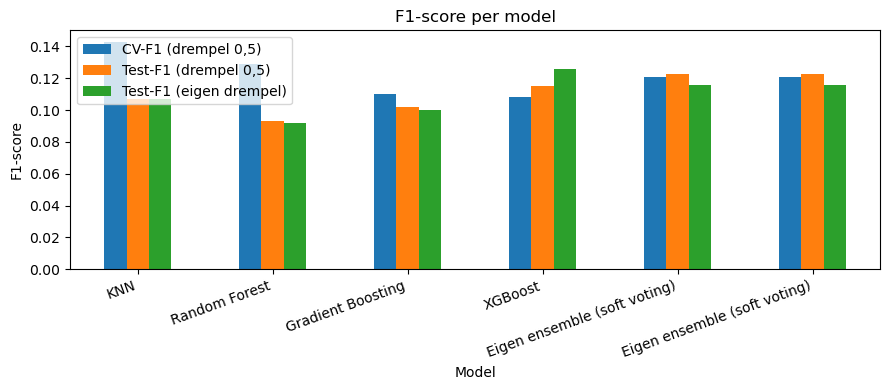

In [ ]:
plot_df = overzicht.set_index("Model")[["CV-F1 (drempel 0,5)", "Test-F1 (drempel 0,5)", "Test-F1 (eigen drempel)"]]
plot_df.plot(kind="bar", figsize=(9, 4))
plt.ylabel("F1-score"); plt.title("F1-score per model"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

#### Overzicht

KNN behaalt de hoogste CV-F1 met 0,143, maar op de testset scoort het eigen soft-voting ensemble het best bij drempel 0,50 met een F1 van 0,123. XGBoost volgt met 0,115 en verbetert met de eigen drempel naar 0,126, terwijl Random Forest en het soft-voting ensemble juist iets slechter scoren met hun aangepaste drempel.
De resultaten laten dus zien dat threshold tuning niet voor elk model verbetering oplevert. De verschillen tussen de modellen zijn bovendien klein, waardoor we in opdracht 4 niet alleen naar de test-F1 kijken, maar ook naar de CV-score en Kaggle-score.

In [ ]:
def maak_submission(model, drempel, bestandsnaam):
    # trainen op alle niet-gestandaardiseerde data (train + test samen);
    # KNN en LR standaardiseren zelf in hun pipeline
    X_ruw = df_model.drop(columns=["stroke"])
    finaal = clone(model).fit(X_ruw, y)

    test = pd.read_csv("test.csv")
    ids = test["id"]
    X_kaggle = test.drop(columns=["id"])
    bool_kolommen = X_kaggle.select_dtypes(include="bool").columns
    X_kaggle[bool_kolommen] = X_kaggle[bool_kolommen].astype(int)
    X_kaggle = X_kaggle[X_ruw.columns]       # zelfde kolomvolgorde als bij het trainen

    kans = finaal.predict_proba(X_kaggle)[:, 1]
    inzending = pd.DataFrame({"id": ids, "stroke": (kans >= drempel).astype(int)})
    inzending.to_csv(bestandsnaam, index=False)
    print(f"{bestandsnaam}: {inzending['stroke'].sum()} van {len(inzending)} patiënten als stroke voorspeld")


#maak_submission(grid_rf.best_estimator_,  drempel_rf,  "submission_rf.csv")
#maak_submission(grid_gb.best_estimator_,  drempel_gb,  "submission_gb.csv")
#maak_submission(grid_xgb.best_estimator_, drempel_xgb, "submission_xgb.csv")
#maak_submission(grid_vc.best_estimator_,  drempel_vc,  "submission_ensemble.csv")
#maak_submission(grid_knn.best_estimator_, drempel_knn, "submission_knn.csv")
maak_submission(grid_lr.best_estimator_,  drempel_lr,  "submission_logistic_regression.csv")

submission_logistic_regression.csv: 524 van 8388 patiënten als stroke voorspeld


/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ab/.local/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


## Bronnen lijst

Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (2e druk). O'Reilly Media.

Müller, A. C., & Guido, S. (2016). *Introduction to machine learning with Python: A guide for data scientists*. O'Reilly Media.

scikit-learn developers. (z.d.-a). *6.3. Preprocessing data*. In *scikit-learn: Machine learning in Python*. Geraadpleegd 30 september 2026, van https://scikit-learn.org/stable/modules/preprocessing.html

scikit-learn developers. (z.d.-b). *Importance of feature scaling*. In *scikit-learn: Machine learning in Python*. Geraadpleegd 30 september 2026, van https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html

Géron, A. (2019). Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow (2e editie). O'Reilly Media. Referentie: https://www.scirp.org/reference/referencespapers?referenceid=3265407

GeeksforGeeks. (z.d.). Handling imbalanced data for classification. https://www.geeksforgeeks.org/machine-learning/handling-imbalanced-data-for-classification/

Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets. Journal of Machine Learning Research, 18(17), 1–5. https://jmlr.org/papers/v18/16-365.html

OpenAI. (2026). ChatGPT-gesprek over tabellen. https://chatgpt.com/c/6ac3e564-085c-83ed-a871-d5dd2dbc2757

OpenAI. (2026). ChatGPT-gesprek over formules in Markdown-stijl. https://chatgpt.com/share/6ac3ea77-0a20-83ed-b2c0-808dc53e5a97

OpenAI. (2026). ChatGPT-gesprek over code. https://chatgpt.com/share/6ac417b9-2e90-83eb-aab0-6b4dfa55a3e3

OpenAI. (2026). ChatGPT-gesprek over de vorm van formules. https://chatgpt.com/share/6ac94a7b-24bc-83ed-af88-3fec0fa52e31

OpenAI. (2026). ChatGPT-gesprek over aanvullende uitleg. https://chatgpt.com/share/6acae7fe-ee38-83ed-8467-ae0368aff622

OpenAI. (2026). ChatGPT-gesprek over de formulevorm. https://chatgpt.com/share/6acaf708-5008-83eb-9f93-6b8739f1142d

Google. (2026). Gemini-gesprek. https://share.gemini.google/vGf9emQ6w3pb

Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and regression trees*. Wadsworth.

Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273-297. https://doi.org/10.1007/BF00994018

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2e druk). Springer.

He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering, 21*(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239

Quinlan, J. R. (1986). Induction of decision trees. *Machine Learning, 1*(1), 81-106. https://doi.org/10.1007/BF00116251

scikit-learn developers. (z.d.-d). *1.4. Support vector machines*. In *scikit-learn: Machine learning in Python*. Geraadpleegd 10 oktober 2026, van https://scikit-learn.org/stable/modules/svm.html

scikit-learn developers. (z.d.-e). *1.10. Decision trees*. In *scikit-learn: Machine learning in Python*. Geraadpleegd 10 oktober 2026, van https://scikit-learn.org/stable/modules/tree.html

scikit-learn developers. (z.d.-f). *Post pruning decision trees with cost complexity pruning*. In *scikit-learn: Machine learning in Python*. Geraadpleegd 10 oktober 2026, van https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html